# 🎵 Informe Técnico: Inteligencia Musical y Predicción de Popularidad en Spotify

**Curso:** Machine Learning (MLY1101) · **Evaluación:** Parcial N°2 (EP2) — Presentación y defensa técnica del proyecto
**Caso de estudio:** Caso C – Spotify Tracks
**Grupo 5:** Diego Marambio · Sebastián Álvarez · Álvaro Sepúlveda · Erick Rosales

---

### Cómo leer y ejecutar este notebook
Este notebook **es el informe técnico**: cada bloque de código va precedido de una explicación de *qué hace y por qué* (🎯) y seguido de la *interpretación del resultado* (📌) con la estructura **objetivo → hallazgo → implicancia para la empresa**.

1. Estructura de carpetas esperada: `data/` (el CSV), `notebooks/` (este archivo), `images/` y `models/` (se generan solos) y `README.md`.
2. Ejecutar con **Entorno de ejecución → Reiniciar y ejecutar todo** (o *Kernel → Restart & Run All*). Todo el notebook corre en menos de 10 minutos y todas las cifras salen de una sola ejecución (semilla fija `random_state=42`).
3. Los textos de interpretación (📌) se redactaron con los resultados de la ejecución con `random_state=42`; si se cambian los datos o las versiones de las librerías, hay que revisar que las cifras citadas sigan coincidiendo.
4. Las rutas son relativas (`../data/...`), por lo que funciona en local y en Colab (en Colab, subir el CSV al panel de archivos o clonar el repositorio).

### Correspondencia con CRISP-DM y con la rúbrica

| Fase CRISP-DM | Sección de este informe | Indicador de la EP2 |
|---|---|---|
| 1. Comprensión del negocio | 1 y 2 | IE5 |
| 2. Comprensión de los datos | 3 y 5 (EDA) | IE5 |
| 3. Preparación de los datos | 4 y 7 | IE5 |
| 4. Modelado | 8 (supervisado) y 9 (no supervisado) | IE6, IE7 |
| 5. Evaluación | 10 | IE8 |
| 6. Despliegue / recomendaciones | 11 | IE5, IE8 |
| Transversal: sesgos, ética y privacidad | 6 | IE5 / IE8 |

### Índice
1. Comprensión del negocio (problema, objetivos, KPIs)
2. Fuentes de datos y herramientas colaborativas
3. Comprensión de los datos: estructura y calidad
4. Preparación de los datos: limpieza y construcción del dataset
5. Análisis exploratorio (EDA) narrativo
6. Sesgos, ética y privacidad
7. Preparación para el modelado (partición sin fuga y *pipeline*)
8. Modelado supervisado (regresión de popularidad)
9. Modelado no supervisado (segmentación de canciones)
10. Evaluación e interpretación de resultados
11. Recomendaciones, despliegue y conclusiones

---
# 1. Comprensión del negocio

### 1.1 Contexto de la industria
Las plataformas de *streaming* reciben miles de lanzamientos diarios. Los sellos discográficos y equipos de **A&R** (*Artists & Repertoire*) deben decidir en qué canciones invertir presupuesto de promoción, producción y posicionamiento en *playlists*. Históricamente esa decisión se ha tomado con criterio subjetivo e intuitivo.

### 1.2 Problema de negocio
> **¿Pueden las características de una canción (audio, género y metadatos) ayudar a priorizar qué temas promocionar, es decir, a anticipar cuáles tienen más probabilidad de ser populares en Spotify?**

Invertir en canciones que no conectan con el público genera ineficiencia financiera. La empresa necesita saber **cuánto** del éxito se puede anticipar con datos del propio tema y **cuánto** depende de factores externos (marketing, comunidad del artista, viralidad).

### 1.3 Objetivos del proyecto
**Objetivo general.** Aplicar el ciclo completo de CRISP-DM sobre el *Spotify Tracks Dataset* para cuantificar en qué medida las características de una canción explican su popularidad, construir y comparar modelos de aprendizaje supervisado y no supervisado, y traducir los resultados en recomendaciones accionables y honestas para un equipo de A&R.

**Objetivos específicos (SMART)**

| | Objetivo | Cómo se mide | Dónde |
|---|---|---|---|
| **S/M** | Limpiar y consolidar el dataset a nivel de canción única, sin fuga de datos | Filas por etapa; 0 canciones de *test* presentes en *train* | Secciones 4 y 7 |
| **S/M** | Cuantificar la relación entre atributos de audio/género y popularidad | Correlaciones, ablación de variables | Secciones 5 y 8 |
| **A/R** | Comparar ≥ 2 modelos supervisados frente a un *baseline* | MAE, RMSE, R², Precisión@5% | Sección 8 |
| **A/R** | Descubrir segmentos de canciones con una técnica no supervisada | Silueta, estabilidad (ARI), perfil de clústeres | Sección 9 |
| **R** | Entregar recomendaciones de uso, límites y riesgos para A&R | Sección de recomendaciones y KPIs de negocio | Secciones 10 y 11 |
| **T** | Entregar informe técnico, notebook ejecutable y README | Entregables de la EP2 | Todo el proyecto |

### 1.4 Definición de KPIs

**Definición operativa de "hit":** canción con `popularity ≥ 70` (escala 0–100).

**KPIs técnicos** (desempeño del modelo, medidos sobre canciones **no vistas** en el entrenamiento):

| KPI técnico | Qué mide | Meta propuesta |
|---|---|---|
| MAE | Error promedio en puntos de popularidad | ≤ 12 puntos y mejora ≥ 25% vs. *baseline* |
| RMSE | Penaliza errores grandes | Reportar (sin meta) |
| R² | Proporción de la varianza explicada | ≥ 0,30 |

> *Las metas iniciales del EP1 (R² ≥ 0,85 y MAE < 5,5) se descartan: el análisis exploratorio (sección 5) muestra que ninguna variable de audio tiene |correlación| ≥ 0,13 con la popularidad, por lo que esas metas eran inalcanzables con estos datos.*

**KPIs de negocio** (lo que le importa a un sello). Se evalúan **seleccionando el 5% de canciones con mayor puntaje del modelo**, como si fuera la lista de temas a promocionar:

| KPI de negocio | Fórmula | Meta propuesta | Línea base |
|---|---|---|---|
| Tasa de hits del catálogo | Canciones con popularidad ≥ 70 / total | Monitoreo | Se calcula en la sección 5 |
| **Precisión@5%** | Hits reales entre el 5% mejor puntuado / canciones seleccionadas | ≥ 15% | = tasa de hits (elegir al azar) |
| **Lift vs. azar** | Precisión@5% / tasa de hits del catálogo | ≥ 3× | 1× |
| Recall@5% | Hits capturados en el 5% seleccionado / total de hits | Monitoreo | 5% (azar) |
| Hits por cada 100 canciones promovidas | Precisión@5% × 100 (modelo vs. azar) | > azar | Tasa de hits × 100 |

> *El KPI "eficiencia de presupuesto A&R" del EP1 se reemplaza por "hits por cada 100 canciones promovidas": el dataset no contiene costos, por lo que el ahorro monetario no es medible; ésta es una variable proxy honesta.*

---
# 2. Fuentes de datos y herramientas colaborativas

### 2.1 Fuente de datos
- **Archivo:** `Spotify_Tracks_Dataset.csv` (114.000 filas × 21 columnas), con atributos de audio equivalentes a los que expone la API Web de Spotify (*audio features*), metadatos de la canción y el género asignado.
- **Variable objetivo:** `popularity` (0–100). Es un índice **propietario de Spotify**, calculado con un algoritmo no público que depende principalmente de la cantidad y recencia de reproducciones. *(Este punto es clave para la sección de sesgos.)*
- **Origen del archivo:** conjunto público en Kaggle que recopiló los datos desde la API de Spotify. > ⚠️ **COMPLETAR antes de entregar:** enlace exacto de descarga y fecha de acceso.

| Variable | Descripción |
|---|---|
| `track_id`, `track_name`, `artists`, `album_name` | Identificadores y metadatos (los artistas múltiples van separados por `;`) |
| `popularity` | Índice 0–100 (variable objetivo) |
| `duration_ms`, `explicit`, `key` (0–11), `mode` (1 = mayor, 0 = menor), `time_signature`, `tempo` (BPM) | Estructura musical |
| `danceability`, `energy`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence` | Indicadores de audio en escala 0–1 |
| `loudness` | Volumen promedio en dB |
| `track_genre` | Género asignado (114 géneros) |

### 2.2 Herramientas y trabajo colaborativo
| Herramienta | Para qué y por qué |
|---|---|
| **Python** (pandas, NumPy, scikit-learn, matplotlib, seaborn) | Estándar de la industria para ciencia de datos; permite un flujo reproducible con *pipelines* |
| **Google Colab / Jupyter** | Notebook único donde código, texto y resultados quedan juntos; sin instalación local |
| **GitHub** | Control de versiones y trabajo en paralelo: cada integrante trabaja en su rama y el historial de *commits* evidencia el aporte individual |

> ⚠️ **COMPLETAR antes de entregar:** enlace al repositorio y una línea que indique qué parte trabajó cada integrante. Solo declarar el uso de GitHub si el historial de *commits* de los cuatro integrantes realmente existe.

---
# 3. Comprensión de los datos: estructura y calidad

### 🎯 3.1 Configuración y carga de datos
**Qué hacemos:** importamos las librerías, fijamos la semilla aleatoria y cargamos el CSV con una **ruta relativa**.
**Por qué:** la semilla (`SEED = 42`) hace que cada ejecución entregue exactamente los mismos números; la ruta relativa evita depender de `/content/...`, que solo existe en Colab. Si el archivo no se encuentra, el notebook se detiene con un mensaje claro en vez de fallar más adelante.

In [ ]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
SEED = 42
HIT = 70                      # umbral operativo de "hit"
np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="crest")
plt.rcParams["figure.dpi"] = 100

os.makedirs("../images", exist_ok=True)
os.makedirs("../models", exist_ok=True)

def guardar(nombre):
    """Guarda la figura actual en images/ (evidencia para el README y la presentación)."""
    plt.savefig(f"../images/{nombre}.png", dpi=130, bbox_inches="tight")

CANDIDATAS = ["../data/Spotify_Tracks_Dataset.csv", "data/Spotify_Tracks_Dataset.csv",
              "Spotify_Tracks_Dataset.csv", "/content/Spotify_Tracks_Dataset.csv"]
DATA_PATH = next((p for p in CANDIDATAS if os.path.exists(p)), None)
assert DATA_PATH is not None, "No se encontró el CSV: colócalo en la carpeta data/."

df_raw = pd.read_csv(DATA_PATH)
print(f"Archivo cargado desde: {DATA_PATH}")
print(f"Dimensiones originales: {df_raw.shape[0]:,} filas x {df_raw.shape[1]} columnas")
display(df_raw.head(3))

Archivo cargado desde: ../data/Spotify_Tracks_Dataset.csv
Dimensiones originales: 114,000 filas x 21 columnas


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.461,1,-6.746,0,0.1430,0.0322,0.000001,0.358,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.166,1,-17.235,1,0.0763,0.9240,0.000006,0.101,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.359,0,-9.734,1,0.0557,0.2100,0.000000,0.117,0.120,76.332,4,acoustic


### 🎯 3.2 Diagnóstico de calidad (antes de limpiar)
**Qué hacemos:** medimos, **sin modificar nada todavía**, todos los problemas de calidad que podrían distorsionar el análisis: duplicados, nulos, identificadores repetidos y valores musicalmente imposibles.
**Por qué:** primero hay que *dimensionar* cada problema para decidir con evidencia qué hacer con él (eliminar, imputar o conservar). Estos controles responden directamente a la retroalimentación del EP1.

In [ ]:
AUDIO = ["danceability", "energy", "loudness", "speechiness", "acousticness",
         "instrumentalness", "liveness", "valence", "tempo", "duration_ms"]

d = df_raw.drop(columns=["Unnamed: 0"], errors="ignore")
d_sin_dup = d.drop_duplicates()

diag = pd.Series({
    "Filas totales": len(d),
    "Duplicados exactos": int(d.duplicated().sum()),
    "Filas con algún nulo": int(d.isnull().any(axis=1).sum()),
    "Celdas nulas (total)": int(d.isnull().sum().sum()),
    "track_id repetidos (tras quitar duplicados exactos)": int(d_sin_dup["track_id"].duplicated().sum()),
    "time_signature = 0": int((d["time_signature"] == 0).sum()),
    "time_signature = 1": int((d["time_signature"] == 1).sum()),
    "tempo = 0": int((d["tempo"] <= 0).sum()),
    "duration_ms = 0": int((d["duration_ms"] <= 0).sum()),
    "popularity = 0 (% de filas)": round(100 * (d["popularity"] == 0).mean(), 2),
    "Géneros distintos": d["track_genre"].nunique(),
}, name="valor", dtype=object)
display(diag.to_frame())

print("\nColumnas con nulos:")
print(d.isnull().sum()[lambda s: s > 0].to_string())
display(d[d.isnull().any(axis=1)][["track_id", "artists", "album_name", "track_name", "track_genre"]])
print("\nResumen estadístico de las variables de audio:")
display(d[AUDIO + ["popularity"]].describe().T.round(3))

,valor
Filas totales,114000
Duplicados exactos,450
Filas con algún nulo,1
Celdas nulas (total),3
track_id repetidos (tras quitar duplicados exactos),23809
time_signature = 0,163
time_signature = 1,973
tempo = 0,157
duration_ms = 0,1
popularity = 0 (% de filas),14.05



Columnas con nulos:
artists       1
album_name    1
track_name    1


,track_id,artists,album_name,track_name,track_genre
65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,k-pop



Resumen estadístico de las variables de audio:


,count,mean,std,min,25%,50%,75%,max
danceability,114000.0,0.567,0.174,0.000,0.456,0.580,0.695,0.985
energy,114000.0,0.641,0.252,0.000,0.472,0.685,0.854,1.000
loudness,114000.0,-8.259,5.029,-49.531,-10.013,-7.004,-5.003,4.532
speechiness,114000.0,0.085,0.106,0.000,0.036,0.049,0.084,0.965
acousticness,114000.0,0.315,0.333,0.000,0.017,0.169,0.598,0.996
instrumentalness,114000.0,0.156,0.310,0.000,0.000,0.000,0.049,1.000
liveness,114000.0,0.214,0.190,0.000,0.098,0.132,0.273,1.000
valence,114000.0,0.474,0.259,0.000,0.260,0.464,0.683,0.995
tempo,114000.0,122.148,29.978,0.000,99.219,122.017,140.071,243.372
duration_ms,114000.0,228029.153,107297.713,0.000,174066.000,212906.000,261506.000,5237295.000


### 📌 Interpretación del diagnóstico de calidad
**Objetivo:** dimensionar los problemas de calidad antes de decidir cómo tratarlos.

**Hallazgo.** El dataset es, en general, limpio: **1 sola fila con nulos** (3 celdas: `artists`, `album_name` y `track_name`; la misma fila tiene `duration_ms = 0`), **450 duplicados exactos** (0,4%), **157 canciones con `tempo = 0`** y **1.136 compases imposibles** (163 con `time_signature = 0` y 973 con valor 1, ≈1%). Dos hallazgos son más relevantes que los anteriores:
- **23.809 `track_id` repetidos.** No son errores: es la misma canción etiquetada en varios géneros. Es el principal riesgo para el modelado porque produce fuga de datos si no se trata (secciones 4.3, 4.4 y 7.1).
- **14% de las filas con `popularity = 0`**, una proporción alta que se analiza en 5.2.

**Implicancia para la empresa.** Los problemas de calidad *clásicos* (nulos, duplicados, valores imposibles) son menores y se corrigen sin perder información relevante. Los problemas *estructurales* (canciones repetidas y ceros de popularidad) son los que pueden distorsionar las conclusiones, y por eso reciben tratamiento específico. Además, `duration_ms` llega hasta ~87 minutos (máx. 5,2 millones de ms), por lo que su cola larga se corrige con logaritmo en la sección 9.

---
# 4. Preparación de los datos: limpieza y construcción del dataset

### 🎯 4.1 Limpieza básica: columna redundante, duplicados exactos y nulos
**Qué hacemos:** eliminamos `Unnamed: 0` (es solo el índice del archivo original), las filas **idénticas** y la fila con valores nulos.
**Por qué:** un índice no aporta información; los duplicados exactos darían doble peso a la misma observación; y la única fila con nulos carece de `artists`, `album_name` y `track_name`, metadatos que usamos en el análisis por artista. Eliminar 1 fila entre más de 113.000 no sesga el resultado.

In [ ]:
embudo = [("Dataset original", len(df_raw))]

df = df_raw.drop(columns=["Unnamed: 0"], errors="ignore")
df = df.drop_duplicates().reset_index(drop=True)
embudo.append(("Sin duplicados exactos", len(df)))

filas_nulas = int(df.isnull().any(axis=1).sum())
df = df.dropna().reset_index(drop=True)
embudo.append((f"Sin filas con nulos ({filas_nulas} fila)", len(df)))

print(f"Filas tras la limpieza básica: {len(df):,}")

Filas tras la limpieza básica: 113,549


### 🎯 4.2 Tratamiento de valores imposibles: `tempo` y `time_signature`
**Qué hacemos:**
- **`tempo = 0`:** eliminamos esas filas. Un tema no puede tener 0 BPM; es un error de la extracción de audio.
- **`time_signature` = 0 o 1:** la API de Spotify documenta compases entre 3 y 7, por lo que 0 y 1 son estimaciones fallidas. Los **reemplazamos por la moda (4/4)**, que es lo más frecuente, para **no perder** esas canciones (≈1% del total).
- **`duration_ms = 0`:** verificamos que no existan.

**Por qué imputar y no eliminar el compás:** eliminar ~1.100 canciones por una sola variable secundaria desperdicia información de las otras 20 columnas. En cambio, `tempo = 0` suele indicar que el análisis de audio falló por completo (por eso se elimina).

In [ ]:
n_tempo0 = int((df["tempo"] <= 0).sum())
n_dur0 = int((df["duration_ms"] <= 0).sum())
n_ts_inval = int((df["time_signature"] < 3).sum())
moda_ts = int(df["time_signature"].mode()[0])

df = df[(df["tempo"] > 0) & (df["duration_ms"] > 0)].reset_index(drop=True)
df.loc[df["time_signature"] < 3, "time_signature"] = moda_ts
embudo.append((f"Sin tempo = 0 ({n_tempo0} filas)", len(df)))

print(f"Filas con tempo = 0 eliminadas: {n_tempo0}")
print(f"Filas con duration_ms = 0: {n_dur0}")
print(f"time_signature inválido imputado a {moda_ts}: {n_ts_inval}")
print("\nDistribución final de time_signature:")
print(df["time_signature"].value_counts().sort_index().to_string())

Filas con tempo = 0 eliminadas: 157
Filas con duration_ms = 0: 0
time_signature inválido imputado a 4: 1130

Distribución final de time_signature:
time_signature
3      9128
4    102459
5      1805


### 🎯 4.3 Consolidación a nivel de canción única (control de fuga de datos)
**Qué hacemos:** una misma canción (`track_id`) aparece varias veces, una por cada género en que fue etiquetada. Verificamos que sus atributos sean idénticos y **consolidamos a una fila por canción**; los géneros se conservan como **variables binarias** (*multi-hot*: la canción puede pertenecer a varios géneros a la vez).
**Por qué:** si dejáramos las filas repetidas y separáramos *train/test* al azar, la misma canción caería en ambos conjuntos y el modelo sería evaluado con temas que **ya vio** (fuga de datos, *data leakage*). La alternativa simple —`drop_duplicates` conservando la primera aparición— dejaría un género **arbitrario** por canción y descartaría información; el *multi-hot* evita ambas cosas.

In [ ]:
CARACT = AUDIO + ["key", "mode", "time_signature", "explicit"]

# 1) ¿Los atributos de una misma canción son idénticos entre sus filas?
max_distintos = df.groupby("track_id")[CARACT].nunique().max().max()
print(f"Máximo de valores distintos por canción en cada característica: {max_distintos}  (1 = idénticos)")

# 2) ¿La popularidad cambia entre géneros para una misma canción?
pop_track = df.groupby("track_id")["popularity"].agg(["min", "max", "mean", "size"])
multi = pop_track[pop_track["size"] > 1]
dif = multi[multi["min"] != multi["max"]]
print(f"track_id repetidos: {int((pop_track['size'] > 1).sum()):,} canciones aparecen en más de un género")
print(f"De ellas, con popularidad distinta según el género: {len(dif):,} ({100*len(dif)/len(multi):.1f}%); "
      f"diferencia máxima: {int((dif['max']-dif['min']).max())} puntos")

# 3) Tabla a nivel (canción, género) para el análisis por género y tabla a nivel canción para modelar
df_filas = df.copy()
tracks = df.drop_duplicates("track_id").set_index("track_id")
tracks["popularity"] = pop_track["mean"]                       # promedio entre géneros (casi siempre idéntico)

gen = pd.crosstab(df["track_id"], df["track_genre"]).clip(upper=1)   # multi-hot
gen.columns = ["gen_" + c for c in gen.columns]
tracks["n_generos"] = gen.sum(axis=1)
tracks = tracks.drop(columns="track_genre").join(gen).reset_index()

tracks["explicit"] = tracks["explicit"].astype(int)
tracks["es_hit"] = (tracks["popularity"] >= HIT).astype(int)
GEN_COLS = [c for c in tracks.columns if c.startswith("gen_")]
embudo.append(("Canciones únicas (por track_id)", len(tracks)))

print(f"\nCanciones únicas: {len(tracks):,} | columnas de género (multi-hot): {len(GEN_COLS)}")
print(f"Canciones etiquetadas con más de un género: {(tracks['n_generos'] > 1).mean():.1%}")

Máximo de valores distintos por canción en cada característica: 1  (1 = idénticos)
track_id repetidos: 16,299 canciones aparecen en más de un género
De ellas, con popularidad distinta según el género: 720 (4.4%); diferencia máxima: 44 puntos

Canciones únicas: 89,583 | columnas de género (multi-hot): 114
Canciones etiquetadas con más de un género: 18.2%


### 🎯 4.4 Segunda fuente de fuga: la misma canción con distinto `track_id`
**Qué hacemos:** buscamos canciones con el **mismo artista y el mismo nombre** pero distinto `track_id` (versión de álbum vs. sencillo, relanzamientos, etc.) y creamos una clave de grupo `grupo`.
**Por qué:** esas versiones tienen audio prácticamente idéntico. Si una cae en *train* y otra en *test*, hay fuga aunque los `track_id` sean distintos. Esta clave se usará en la partición (sección 7) para que **todas las versiones de una canción queden en el mismo conjunto**.

In [ ]:
tracks["grupo"] = (tracks["artists"].str.lower().str.strip() + "|" +
                   tracks["track_name"].str.lower().str.strip())

n_grupos = tracks["grupo"].nunique()
extra = len(tracks) - n_grupos
print(f"Canciones únicas por track_id: {len(tracks):,}")
print(f"Grupos distintos (artista + nombre): {n_grupos:,}")
print(f"Filas que son otra versión de una canción ya presente: {extra:,} ({100*extra/len(tracks):.1f}%)")

resumen_embudo = pd.DataFrame(embudo, columns=["Etapa", "Filas"])
resumen_embudo["Filas eliminadas"] = (-resumen_embudo["Filas"].diff()).fillna(0).astype(int)
display(resumen_embudo)

Canciones únicas por track_id: 89,583
Grupos distintos (artista + nombre): 81,061
Filas que son otra versión de una canción ya presente: 8,522 (9.5%)


,Etapa,Filas,Filas eliminadas
0,Dataset original,114000,0
1,Sin duplicados exactos,113550,450
2,Sin filas con nulos (1 fila),113549,1
3,Sin tempo = 0 (157 filas),113392,157
4,Canciones únicas (por track_id),89583,23809


### 📌 Interpretación de la preparación
**Hallazgo.** El dataset pasó de **114.000 filas a 89.583 canciones únicas** (−21%): 450 duplicados exactos, 1 fila con nulos, 157 con `tempo = 0` y 23.809 filas repetidas por multi-género. Además:
- El **18,2%** de las canciones pertenece a más de un género, por eso los géneros se codifican como *multi-hot* en vez de forzar uno solo.
- Para las canciones repetidas, la popularidad difiere entre géneros en solo **720 de 16.299 casos (4,4%)**, así que promediarla es una decisión prácticamente inocua.
- Otro **9,5%** (8.522 canciones) son versiones de una canción ya presente con distinto `track_id`; se controlan agrupando en la partición *train/test*.

**Implicancia para la empresa.** El "tamaño real" del catálogo analizable es de **89.583 canciones, no 114.000**, y la tasa de hits correcta es **3,48%** (3.119 hits), no el 4,8% que aparece al contar filas repetidas. Reportar cifras sobre filas repetidas infla los resultados.

---
# 5. Análisis exploratorio (EDA) narrativo

> **Hilo conductor:** pregunta de negocio → ¿cómo se distribuye lo que queremos predecir? → ¿qué datos son confiables? → ¿las características de audio explican la popularidad? → ¿qué significa para la empresa? → ¿qué preparamos para modelar?

### 🎯 5.1 ¿Cómo se distribuye la popularidad? (variable objetivo)
**Objetivo:** entender qué estamos intentando predecir y qué tan raro es un "hit".
**Qué hacemos:** histograma de la popularidad (con y sin los ceros) y cálculo de la tasa de hits.

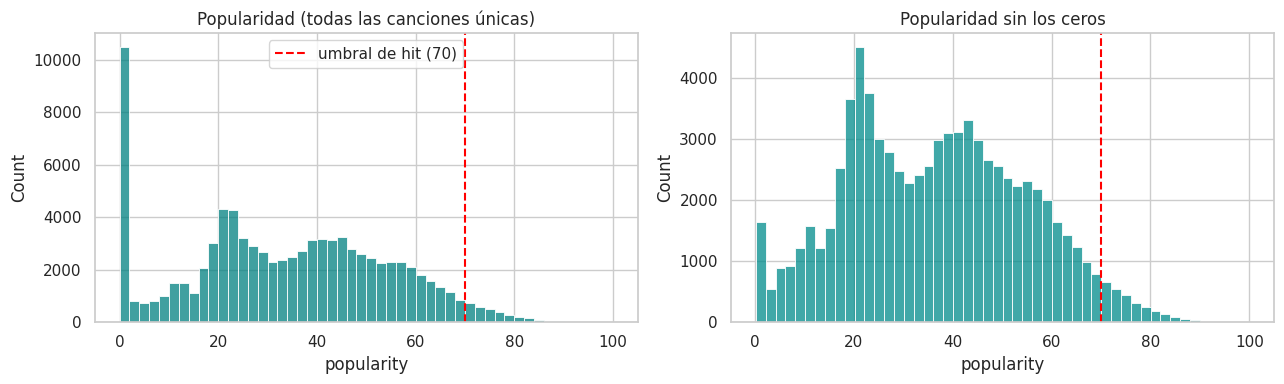

Canciones únicas: 89,583
Popularidad media: 33.2 | mediana: 33.0 | desv. estándar: 20.6
Popularidad = 0: 10.4%
Hits (popularidad >= 70): 3,119  ->  tasa de hits del catálogo = 3.48%


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(tracks["popularity"], bins=50, ax=ax[0], color="teal")
ax[0].axvline(HIT, color="red", ls="--", label=f"umbral de hit ({HIT})")
ax[0].set_title("Popularidad (todas las canciones únicas)"); ax[0].set_xlabel("popularity"); ax[0].legend()
sns.histplot(tracks.loc[tracks["popularity"] > 0, "popularity"], bins=50, ax=ax[1], color="darkcyan")
ax[1].axvline(HIT, color="red", ls="--")
ax[1].set_title("Popularidad sin los ceros"); ax[1].set_xlabel("popularity")
plt.tight_layout(); guardar("01_distribucion_popularidad"); plt.show()

TASA_HITS = tracks["es_hit"].mean()
print(f"Canciones únicas: {len(tracks):,}")
print(f"Popularidad media: {tracks['popularity'].mean():.1f} | mediana: {tracks['popularity'].median():.1f} | desv. estándar: {tracks['popularity'].std():.1f}")
print(f"Popularidad = 0: {(tracks['popularity'] == 0).mean():.1%}")
print(f"Hits (popularidad >= {HIT}): {int(tracks['es_hit'].sum()):,}  ->  tasa de hits del catálogo = {TASA_HITS:.2%}")

### 📌 Interpretación: distribución de la popularidad
**Objetivo → hallazgo → implicancia.**
- **Hallazgo:** la popularidad se concentra en la zona media-baja de la escala (media 33,2; mediana 33,0). Hay un pico artificial en **0** (10,4% de las canciones únicas; era 14% al contar filas repetidas) y los **hits son raros: solo 3,48%** (3.119 de 89.583).
- **Implicancia:** un hit es un evento infrecuente, por lo que la *exactitud* (*accuracy*) sería engañosa: un modelo que dijera "ninguna canción es hit" acertaría el 96,5% de las veces y sería inútil. Por eso evaluamos con métricas de *ranking* (Precisión@5%, Lift, PR-AUC). Elegir canciones al azar acierta apenas ~3,5% de las veces: esa es la línea base a superar.

### 🎯 5.2 ¿Qué significan los ceros? Popularidad por género
**Objetivo:** decidir con evidencia si los ceros de popularidad son *impopularidad real* o un problema de los datos.
**Qué hacemos:** calculamos, por género, el porcentaje de canciones con popularidad 0 y la popularidad media. Usamos la tabla a nivel (canción, género) porque aquí cada observación es un par canción–género.

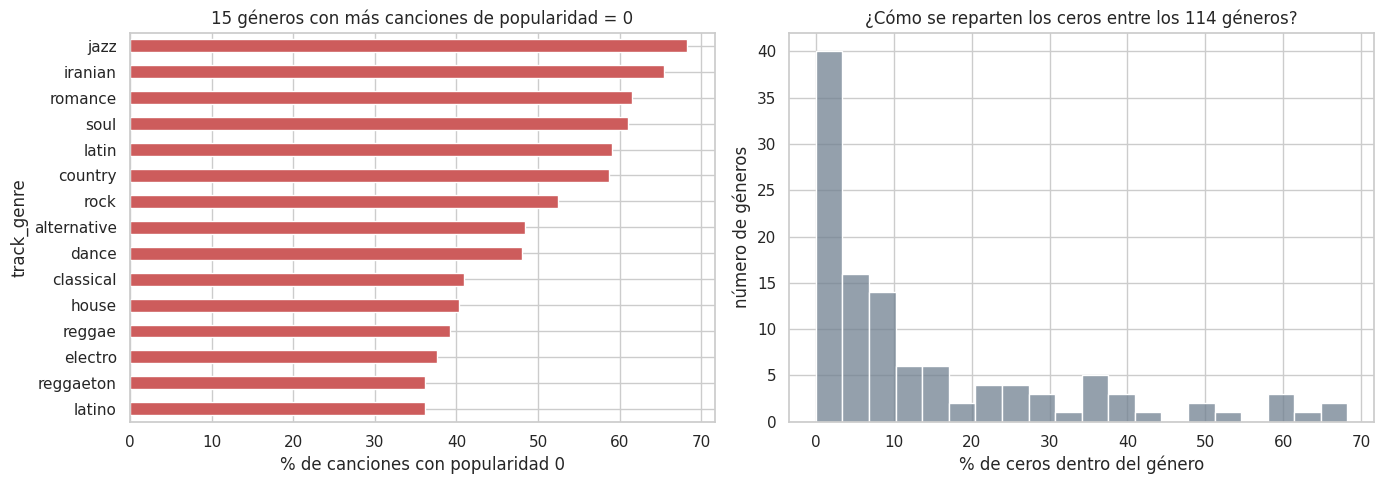

Géneros sin ningún cero: 3 de 114
Géneros con más de 50% de ceros: 7

Top 10 géneros por % de ceros:
             media  pct_ceros     n
track_genre                        
jazz          13.5       68.2   998
iranian        2.2       65.4   984
romance        3.5       61.5   903
soul          19.8       61.1   999
latin          8.4       59.1   990
country       17.0       58.7  1000
rock          19.0       52.5  1000
alternative   24.4       48.4   999
dance         23.4       48.0   965
classical     13.5       40.9   933

Promedio de audio según si la popularidad es 0 o no:


,popularidad > 0,popularidad = 0,diferencia %
danceability,0.564,0.556,-1.414
energy,0.642,0.578,-9.897
loudness,-8.423,-8.924,5.947
speechiness,0.089,0.074,-16.490
acousticness,0.321,0.390,21.667
instrumentalness,0.178,0.126,-29.178
liveness,0.220,0.190,-13.626
valence,0.469,0.484,3.166
tempo,122.715,118.466,-3.463
duration_ms,231020.618,213993.741,-7.370


In [ ]:
por_genero = df_filas.groupby("track_genre")["popularity"].agg(
    media="mean", pct_ceros=lambda s: 100 * (s == 0).mean(), n="size")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
por_genero["pct_ceros"].sort_values(ascending=False).head(15)[::-1].plot(kind="barh", ax=ax[0], color="indianred")
ax[0].set_title("15 géneros con más canciones de popularidad = 0"); ax[0].set_xlabel("% de canciones con popularidad 0")
sns.histplot(por_genero["pct_ceros"], bins=20, ax=ax[1], color="slategray")
ax[1].set_title("¿Cómo se reparten los ceros entre los 114 géneros?")
ax[1].set_xlabel("% de ceros dentro del género"); ax[1].set_ylabel("número de géneros")
plt.tight_layout(); guardar("02_ceros_por_genero"); plt.show()

print(f"Géneros sin ningún cero: {(por_genero['pct_ceros'] == 0).sum()} de {len(por_genero)}")
print(f"Géneros con más de 50% de ceros: {(por_genero['pct_ceros'] > 50).sum()}")
print("\nTop 10 géneros por % de ceros:")
print(por_genero.sort_values("pct_ceros", ascending=False).head(10).round(1).to_string())

# ¿Las canciones con popularidad 0 suenan distinto a las demás?
comp = tracks.groupby(tracks["popularity"] == 0)[AUDIO].mean().T
comp.columns = ["popularidad > 0", "popularidad = 0"]
comp["diferencia %"] = (comp["popularidad = 0"] / comp["popularidad > 0"] - 1) * 100
print("\nPromedio de audio según si la popularidad es 0 o no:")
display(comp.round(3))

### 📌 Interpretación: los ceros de popularidad
**Objetivo:** decidir si un 0 significa "nadie la escucha" o "dato no confiable".

**Hallazgo.**
- Los ceros **no se reparten al azar**: 3 de 114 géneros no tienen ninguno, mientras que **7 géneros tienen más de la mitad de sus canciones en 0** (jazz 68%, *iranian* 65%, *romance* 62%, *soul* 61%, *latin* 59%, *country* 59%, *rock* 53%). Incluso géneros masivos como *rock*, *country* y *dance* (48%) tienen la mitad de su catálogo en 0.
- Las canciones con popularidad 0 suenan algo distinto (**+22% de acousticness, −29% de instrumentalness, −16% de speechiness, −10% de energy**), diferencia coherente con que se concentran en ciertos géneros, no con que sean "peores".

**Interpretación (hipótesis).** Que la mitad de las canciones de *rock* o *country* sea realmente impopular es poco creíble. Es más plausible que parte de los ceros sea un **artefacto de la fuente** (canciones sin datos de reproducciones al momento de la extracción). Con este dataset **no podemos demostrarlo**, solo mostrar que el patrón es inconsistente con una impopularidad real.

**Decisión.** Conservamos los ceros (no hay base objetiva para eliminarlos), pero medimos su efecto en una **prueba de sensibilidad** (8.6) y lo declaramos como sesgo (sección 6).

**Implicancia para la empresa.** Los géneros con muchos ceros quedan subvalorados; cualquier ranking de géneros por popularidad en este dataset debe tomarse con cautela.

### 🎯 5.3 La pregunta central: ¿las características de audio explican la popularidad?
**Objetivo:** responder la pregunta clave del caso.
**Qué hacemos:** correlación de Pearson entre cada atributo y `popularity`, y matriz de correlación entre los propios atributos de audio (para detectar variables redundantes que afecten a los modelos lineales).

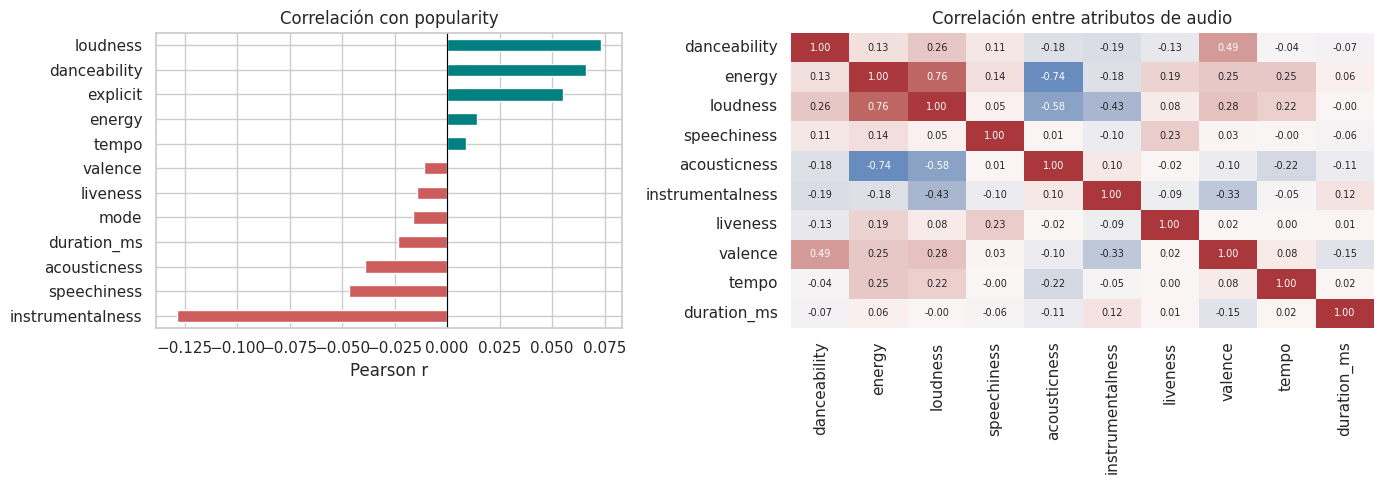

Correlación con popularity (ordenada):
instrumentalness   -0.129
speechiness        -0.047
acousticness       -0.039
duration_ms        -0.023
mode               -0.016
liveness           -0.014
valence            -0.011
tempo               0.009
energy              0.014
explicit            0.055
danceability        0.066
loudness            0.073

Mayor |r| con la popularidad: 0.129
R² teórico de la mejor variable individual (r²): 0.017


In [ ]:
VARS_CORR = AUDIO + ["explicit", "mode"]
corr_pop = tracks[VARS_CORR + ["popularity"]].corr()["popularity"].drop("popularity").sort_values()

fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.25]})
colores = ["indianred" if v < 0 else "teal" for v in corr_pop]
corr_pop.plot(kind="barh", ax=ax[0], color=colores)
ax[0].axvline(0, color="black", lw=0.8); ax[0].set_title("Correlación con popularity"); ax[0].set_xlabel("Pearson r")
sns.heatmap(tracks[AUDIO].corr(), annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax[1], annot_kws={"size": 7}, cbar=False)
ax[1].set_title("Correlación entre atributos de audio")
plt.tight_layout(); guardar("03_correlaciones"); plt.show()

print("Correlación con popularity (ordenada):")
print(corr_pop.round(3).to_string())
print(f"\nMayor |r| con la popularidad: {corr_pop.abs().max():.3f}")
print(f"R² teórico de la mejor variable individual (r²): {corr_pop.abs().max()**2:.3f}")

### 📌 Interpretación: ¿el audio explica la popularidad?
**Objetivo:** responder la pregunta central del caso.

**Hallazgo.** **Ninguna variable de audio supera |r| = 0,13**. La más fuerte es `instrumentalness` (r = −0,129: a más instrumental, menos popular), seguida de `loudness` (+0,073), `danceability` (+0,066) y `explicit` (+0,055). La mejor variable individual explica solo **r² = 1,7%** de la varianza de la popularidad. En el mapa de calor se ve además que `energy`, `loudness` y `acousticness` están fuertemente correlacionadas entre sí (r = 0,76 entre energy y loudness; −0,74 entre energy y acousticness), lo que justifica usar regularización en el modelo lineal.

**Implicancia para la empresa.** Un atributo de audio aislado **no sirve como criterio para decidir qué promover**. Dos matices importantes: (1) Pearson solo detecta relaciones lineales, por eso lo verificamos con modelos no lineales en la sección 8.4; (2) correlación no es causalidad. Factores no medidos en este dataset (promoción, tamaño de la audiencia del artista, inclusión en *playlists*) podrían estar detrás, pero **este dataset no permite comprobarlo**.

### 🎯 5.4 Variables categóricas: ¿importan el contenido explícito, el modo o el compás?
**Objetivo:** revisar si alguna variable discreta separa mejor la popularidad que los atributos continuos.
**Qué hacemos:** popularidad media y tasa de hits por categoría.

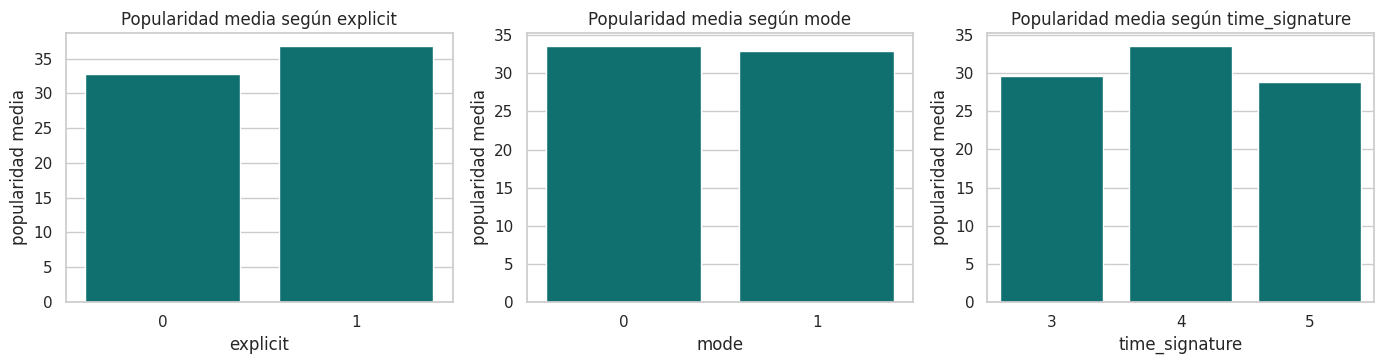


explicit:
          canciones  pop_media  tasa_hits
explicit                                 
0             81879      32.85       3.13
1              7704      36.88       7.26

mode:
      canciones  pop_media  tasa_hits
mode                                 
0         32529      33.64       3.74
1         57054      32.94       3.33

time_signature:
                canciones  pop_media  tasa_hits
time_signature                                 
3                    7604      29.60       2.22
4                   80394      33.62       3.64
5                    1585      28.79       1.39


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, col in zip(ax, ["explicit", "mode", "time_signature"]):
    sns.barplot(data=tracks, x=col, y="popularity", ax=a, color="teal", errorbar=None)
    a.set_title(f"Popularidad media según {col}"); a.set_ylabel("popularidad media")
plt.tight_layout(); guardar("04_categoricas"); plt.show()

for col in ["explicit", "mode", "time_signature"]:
    t = tracks.groupby(col).agg(canciones=("popularity", "size"), pop_media=("popularity", "mean"), tasa_hits=("es_hit", "mean"))
    t["tasa_hits"] = (100 * t["tasa_hits"]).round(2)
    print(f"\n{col}:"); print(t.round(2).to_string())

### 📌 Interpretación: variables categóricas
**Hallazgo.**
- **`explicit`** es la variable discreta con mayor diferencia: las canciones explícitas son el 8,6% del catálogo (7.704) pero tienen **tasa de hits de 7,3% frente a 3,1%** (≈ 2,3 veces) y popularidad media de 36,9 vs. 32,9.
- **`mode`** (mayor/menor) casi no hace diferencia (33,6 vs. 32,9; hits 3,7% vs. 3,3%).
- **`time_signature`**: el compás 4/4 tiene más hits (3,6%) que 3/4 (2,2%) y 5/4 (1,4%), pero con diferencias pequeñas.

**Implicancia para la empresa.** La diferencia de `explicit` probablemente refleja los **géneros** que dominan los hits actuales (hipótesis no verificada), no un efecto del contenido explícito en sí. **No debe interpretarse como "agregar contenido explícito aumenta la popularidad"**; sería una conclusión causal que los datos no sostienen (y éticamente cuestionable).

### 🎯 5.5 Ranking de artistas con un mínimo de canciones
**Objetivo:** identificar artistas con tracción *consistente*.
**Qué hacemos:** separamos las colaboraciones (`;`) para contar a cada artista individualmente y exigimos **al menos 10 canciones**. Sin ese mínimo, un artista con una sola canción muy popular encabeza el ranking por azar.

SIN mínimo de canciones (ranking engañoso):
               media  canciones
artists                        
Bizarrap        99.0          1
Quevedo         99.0          1
Harry Styles    92.0          3
Luar La L       90.5          1
Beach Weather   90.0          1

CON mínimo de 10 canciones (2707 de 29,794 artistas cumplen):
                   media  canciones
artists                            
Frank Ocean         74.1         21
Radiohead           73.5         11
The Neighbourhood   73.5         27
System Of A Down    72.8         12
Stray Kids          72.6         23
TWICE               72.5         17
Travis Scott        72.3         23
SEVENTEEN           70.5         15
j-hope              70.4         12
Ariana Grande       70.3         18


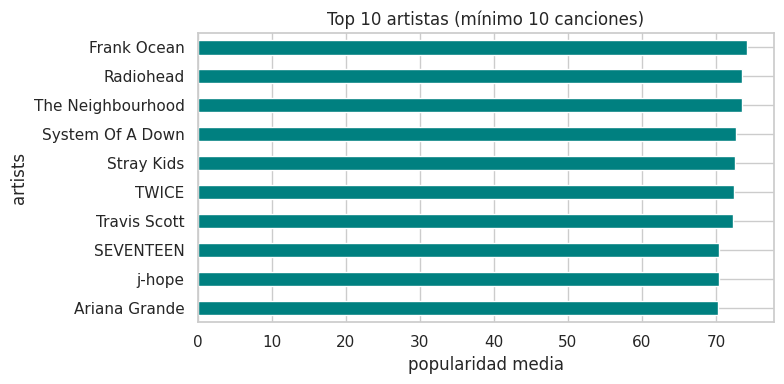

In [ ]:
art = tracks[["artists", "popularity"]].assign(artists=tracks["artists"].str.split(";")).explode("artists")
art["artists"] = art["artists"].str.strip()
st = art.groupby("artists")["popularity"].agg(media="mean", canciones="size")

print("SIN mínimo de canciones (ranking engañoso):")
print(st.sort_values("media", ascending=False).head(5).round(1).to_string())

top_art = st[st["canciones"] >= 10].sort_values("media", ascending=False).head(10)
print(f"\nCON mínimo de 10 canciones ({(st['canciones'] >= 10).sum()} de {len(st):,} artistas cumplen):")
print(top_art.round(1).to_string())

plt.figure(figsize=(8, 4))
top_art["media"][::-1].plot(kind="barh", color="teal")
plt.xlabel("popularidad media"); plt.title("Top 10 artistas (mínimo 10 canciones)")
plt.tight_layout(); guardar("05_top_artistas"); plt.show()

### 📌 Interpretación: ranking de artistas
**Hallazgo.** Sin mínimo de canciones, el ranking lo encabezan Bizarrap y Quevedo con 99 puntos, **pero con una sola canción cada uno**: un resultado del azar, no de consistencia. Al exigir ≥ 10 canciones solo califican **2.707 de 29.794 artistas (9%)** y el ranking pasa a artistas con tracción sostenida (Frank Ocean 74,1; Radiohead 73,5; The Neighbourhood 73,5; …), todos entre 70 y 74 puntos.

**Implicancia para la empresa.** La popularidad sostenida está asociada a **artistas consolidados**, información que el modelo **no usa** (por privacidad y porque no existiría para artistas nuevos). Esto refuerza que el sonido por sí solo no es el factor decisivo y advierte un **sesgo de popularidad previa**: el modelo sirve para "lo que ya funciona", no para descubrir talento emergente.

### 📌 Síntesis del EDA: qué le decimos a la empresa
| Pregunta | Respuesta basada en los datos | Consecuencia para el modelado |
|---|---|---|
| ¿Qué tan confiables son los datos? | Limpios en lo básico; los **ceros** y las **canciones repetidas** requieren tratamiento | Consolidar por canción y partir por grupos |
| ¿Qué tan raro es un hit? | Solo **3,5%** de las canciones | Evaluar con métricas de *ranking*, no con *accuracy* |
| ¿El audio explica la popularidad? | **Casi no** (\|r\| < 0,13 por variable) | Esperar bajo poder predictivo del audio solo |
| ¿Qué más se asocia a la popularidad? | El **género** (ceros y popularidad varían mucho entre géneros) y, secundariamente, `explicit` | Incluir el género; verificar su aporte con una ablación |
| ¿Qué riesgos tiene la fuente? | Métrica propietaria, cuota fija por género y ceros sospechosos | Medir sensibilidad y declarar los sesgos (sección 6) |

---
# 6. Sesgos, ética y privacidad

### 🎯 6.1 Evidencia del sesgo de selección del catálogo
**Qué hacemos:** revisamos cuántas canciones tiene cada género en el archivo original.
**Por qué:** si el dataset fue armado con una cuota fija por género, no es una muestra representativa del mercado real y eso limita lo que el modelo puede decirle a la empresa.

In [ ]:
conteo = df_raw["track_genre"].value_counts()
print(f"Canciones por género en el archivo original -> mín: {conteo.min()} | mediana: {int(conteo.median())} | máx: {conteo.max()}")
print(f"Géneros con exactamente 1.000 filas: {(conteo == 1000).sum()} de {len(conteo)}")

Canciones por género en el archivo original -> mín: 1000 | mediana: 1000 | máx: 1000
Géneros con exactamente 1.000 filas: 114 de 114


### 📌 6.2 Sesgos identificados
| Sesgo | Evidencia en este proyecto | Efecto sobre el modelo / la empresa |
|---|---|---|
| **Sesgo de la fuente (el más importante)** | `popularity` es una métrica **propietaria de Spotify**, cuyo cálculo no es público y que refleja lo que la propia plataforma muestra y promueve | El modelo aprende a **reproducir las decisiones de Spotify**, no a detectar calidad musical. Es circular: lo promovido se vuelve popular y lo popular se promueve |
| **Sesgo de selección** | **Los 114 géneros tienen exactamente 1.000 canciones** en el archivo original (sección 6.1): una cuota artificial que no refleja el catálogo real | La tasa de hits y la importancia del género no son extrapolables al mercado real |
| **Sesgo por datos faltantes / ceros** | Los ceros se concentran en ciertos géneros (sección 5.2), incluso masivos como *rock* o *country*, lo que difícilmente es impopularidad real | Géneros como jazz, *iranian* o *romance* quedan mal representados y serían sistemáticamente subvalorados |
| **Sesgo de popularidad previa** | Los artistas del *top* son figuras ya consolidadas (sección 5.5) | Sirve para "lo que ya funciona", no para descubrir talento nuevo |

### 📌 6.3 Consideraciones éticas
- **Apoyo a la decisión, no automatización:** el modelo no debe usarse para descartar artistas, géneros o contratos; solo para ordenar una lista que un equipo de A&R luego revisa.
- **Riesgo de homogeneización cultural:** promover solo lo que "se parece a un hit" reduce la diversidad musical y perpetúa los géneros ya dominantes.
- **Equidad entre géneros:** como los ceros se concentran en ciertos géneros, el modelo podría penalizarlos sistemáticamente (ver sección 10).

### 📌 6.4 Privacidad y marco normativo
- No hay datos de oyentes, pero los **nombres de los artistas son datos personales** de personas reales identificables.
- **Marco normativo:** Ley 19.628 sobre protección de la vida privada y la nueva Ley 21.719 sobre protección de datos personales (Chile); el **GDPR** de la Unión Europea como referencia internacional.
- El uso comercial de los datos debe respetar los **términos de uso de la API de Spotify**.
- Buenas prácticas aplicadas: el modelo **no usa** el nombre del artista como variable (solo audio, género y metadatos musicales), reduciendo el riesgo de discriminar por persona.

---
# 7. Preparación para el modelado

### 🎯 7.1 Partición *train/test* sin fuga de datos
**Qué hacemos:** separamos 80% / 20% con `GroupShuffleSplit`, agrupando por `grupo` (artista + nombre). Todas las versiones de una misma canción quedan en el mismo conjunto. Además, **demostramos** el problema comparando con una partición aleatoria simple.
**Por qué:** el *test* debe simular canciones **nuevas** que el modelo nunca vio; de lo contrario las métricas salen optimistas. El grupo es la unidad de la fuga, no la fila.

In [ ]:
from sklearn.model_selection import GroupShuffleSplit, train_test_split

NUM_COLS = AUDIO + ["mode", "explicit"]      # numéricas -> se estandarizan
CAT_COLS = ["key", "time_signature"]         # categóricas -> one-hot (la tonalidad no es una escala ordenada)
FEAT_COLS = NUM_COLS + CAT_COLS + GEN_COLS

X = tracks[FEAT_COLS]
y = tracks["popularity"]
grupos = tracks["grupo"]

idx_tr, idx_te = next(GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED).split(X, y, groups=grupos))
X_train, X_test = X.iloc[idx_tr], X.iloc[idx_te]
y_train, y_test = y.iloc[idx_tr].to_numpy(), y.iloc[idx_te].to_numpy()
g_train = grupos.iloc[idx_tr]

# Verificación anti-fuga con la partición definitiva
fuga_grupo = len(set(grupos.iloc[idx_tr]) & set(grupos.iloc[idx_te]))
fuga_id = tracks.iloc[idx_te]["track_id"].isin(tracks.iloc[idx_tr]["track_id"]).mean()

# Comparación: partición aleatoria simple (la que se usó en el EP1)
i_a, i_b = train_test_split(np.arange(len(tracks)), test_size=0.20, random_state=SEED)
fuga_ingenua = tracks.iloc[i_b]["grupo"].isin(set(tracks.iloc[i_a]["grupo"])).mean()

print(f"Entrenamiento: {len(X_train):,} canciones | Prueba: {len(X_test):,} canciones")
print(f"Partición aleatoria simple -> canciones de prueba cuya canción ya está en train: {fuga_ingenua:.1%}")
print(f"Partición por grupos (usada) -> grupos compartidos: {fuga_grupo} | track_id compartidos: {fuga_id:.1%}")
print(f"Tasa de hits -> train: {(y_train >= HIT).mean():.2%} | test: {(y_test >= HIT).mean():.2%}")

Entrenamiento: 71,727 canciones | Prueba: 17,856 canciones
Partición aleatoria simple -> canciones de prueba cuya canción ya está en train: 13.2%
Partición por grupos (usada) -> grupos compartidos: 0 | track_id compartidos: 0.0%
Tasa de hits -> train: 3.50% | test: 3.40%


### 📌 Interpretación de la partición
**Hallazgo.** Una partición aleatoria simple dejaría al **13,2%** de las canciones de prueba con una versión de la misma canción en el entrenamiento. La partición por grupos usada aquí tiene **0 grupos y 0% de `track_id` compartidos**. Además, la tasa de hits es similar en entrenamiento (3,50%) y prueba (3,40%), por lo que ambos conjuntos son representativos.

**Implicancia.** Las métricas que siguen miden el desempeño sobre **canciones realmente nuevas**, que es la situación en la que la empresa usaría el modelo. (En el EP1 la fuga era de ~32% por no haber tratado los `track_id` repetidos.)

### 🎯 7.2 *Pipeline* de preprocesamiento
**Qué hacemos:** definimos un `ColumnTransformer` que (a) **estandariza** las variables numéricas, (b) aplica **one-hot** a `key` y `time_signature` y (c) deja pasar sin cambios las columnas binarias de género.
**Por qué:** incluir el preprocesamiento *dentro* del `Pipeline` garantiza que el escalador se ajuste **solo con los datos de entrenamiento** (en validación cruzada, solo con cada pliegue de entrenamiento) y así no se filtra información del *test*. La estandarización es necesaria para el modelo lineal (Ridge); es inocua para los árboles.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

def make_prep(num=NUM_COLS, cat=CAT_COLS, gen=GEN_COLS):
    pasos = []
    if num: pasos.append(("num", StandardScaler(), num))
    if cat: pasos.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat))
    if gen: pasos.append(("gen", "passthrough", gen))
    return ColumnTransformer(pasos, sparse_threshold=0)

prep_demo = make_prep().fit(X_train)
print(f"Variables de entrada: {len(FEAT_COLS)} -> columnas tras el preprocesamiento: {prep_demo.transform(X_train.head(5)).shape[1]}")
print(f"  numéricas: {len(NUM_COLS)} | categóricas (one-hot): {len(CAT_COLS)} | género (multi-hot): {len(GEN_COLS)}")

Variables de entrada: 128 -> columnas tras el preprocesamiento: 141
  numéricas: 12 | categóricas (one-hot): 2 | género (multi-hot): 114


---
# 8. Modelado supervisado: regresión de la popularidad

**Problema:** `popularity` es una variable continua (0–100), por lo tanto es un problema de **regresión**. Más adelante (8.5) lo complementamos con un clasificador de *hits* para medir los KPIs de negocio.

### 🎯 8.1 Modelos elegidos y justificación
| Modelo | Por qué lo elegimos | Qué esperamos |
|---|---|---|
| **Baseline (`DummyRegressor`, predice la media)** | Referencia mínima: cualquier modelo útil debe superarlo | R² ≈ 0 |
| **Ridge (regresión lineal regularizada)** | Simple e **interpretable**; la regularización controla la multicolinealidad que vimos entre `energy`, `loudness` y `acousticness` | Capta relaciones lineales; probablemente limitado |
| **Random Forest** | Capta no linealidades e interacciones (ej. audio × género) sin necesidad de escalar; robusto al ruido | Podría superar a Ridge si existen interacciones audio × género; el sobreajuste se controla con `max_depth` y `min_samples_leaf` |
| **HistGradientBoosting** | Boosting eficiente para datos tabulares; suele ser el mejor algoritmo en este tipo de datos | Mejor desempeño, con más hiperparámetros por ajustar |

**Configuración:** los hiperparámetros se eligen con **validación cruzada agrupada** (`GroupKFold`, 3 pliegues) **solo sobre el conjunto de entrenamiento**, optimizando el **MAE**, porque se interpreta directamente como "puntos de popularidad de error". El conjunto de prueba se usa **una sola vez**, al final.

In [ ]:
import time
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

cv = GroupKFold(n_splits=3)

candidatos = {
    "Ridge": (Ridge(),
              {"modelo__alpha": [1, 10, 100, 1000]}),
    "Random Forest": (RandomForestRegressor(n_estimators=60, max_features=0.3, n_jobs=-1, random_state=SEED),
                      {"modelo__max_depth": [10, 16], "modelo__min_samples_leaf": [10]}),
    "HistGradientBoosting": (HistGradientBoostingRegressor(random_state=SEED),
                             {"modelo__learning_rate": [0.05, 0.1], "modelo__max_leaf_nodes": [31, 63]}),
}

modelos, filas_cv = {}, []
for nombre, (est, grilla) in candidatos.items():
    t0 = time.time()
    gs = GridSearchCV(Pipeline([("prep", make_prep()), ("modelo", est)]), grilla, cv=cv,
                      scoring="neg_mean_absolute_error", n_jobs=1, refit=True)
    gs.fit(X_train, y_train, groups=g_train)
    modelos[nombre] = gs.best_estimator_
    filas_cv.append({"Modelo": nombre, "Mejores hiperparámetros": {k.replace("modelo__", ""): v for k, v in gs.best_params_.items()},
                     "MAE (validación cruzada)": -gs.best_score_, "Tiempo (s)": round(time.time() - t0, 1)})
    print(f"{nombre}: listo en {time.time() - t0:.0f} s")

base = Pipeline([("prep", make_prep()), ("modelo", DummyRegressor(strategy="mean"))]).fit(X_train, y_train)
modelos = {"Baseline (media)": base, **modelos}
display(pd.DataFrame(filas_cv).round(3))

Ridge: listo en 3 s
Random Forest: listo en 83 s
HistGradientBoosting: listo en 62 s


,Modelo,Mejores hiperparámetros,MAE (validación cruzada),Tiempo (s)
0,Ridge,{'alpha': 1},11.922,2.6
1,Random Forest,"{'max_depth': 16, 'min_samples_leaf': 10}",14.111,83.0
2,HistGradientBoosting,"{'learning_rate': 0.1, 'max_leaf_nodes': 63}",11.373,61.7


### 📌 Interpretación de la validación cruzada
**Hallazgo.** En validación cruzada (solo con datos de entrenamiento), el mejor modelo es **HistGradientBoosting (MAE 11,37)**, seguido de **Ridge (11,92)**; **Random Forest queda último (14,11)**, contrario a lo esperado.

**Interpretación.** Una explicación posible es que, de las 141 columnas, 114 son géneros binarios muy dispersos; con `max_features = 0.3` y profundidad limitada, cada árbol del bosque dispone de pocas variables informativas en cada división, mientras que el *boosting* las aprovecha mejor. Es una hipótesis: no se exploró más el bosque por tiempo de cómputo.

**Limitación a declarar.** Varios hiperparámetros elegidos quedaron **en el borde de la grilla** (Ridge `alpha = 1`, el menor; HGB con 63 hojas y `learning_rate = 0,1`, los mayores; RF con `max_depth = 16`, el mayor). Una búsqueda más amplia podría mejorar algo los resultados.

### 🎯 8.2 Evaluación en el conjunto de prueba
**Qué hacemos:** evaluamos cada modelo **en entrenamiento y en prueba** con R², MAE, RMSE y el porcentaje de predicciones a ≤ 10 puntos del valor real.
**Por qué:** comparar entrenamiento vs. prueba permite detectar **sobreajuste**; comparar contra el *baseline* mide cuánto valor agrega realmente el modelo.

,R² train,R² test,MAE train,MAE test,RMSE test,% a ≤10 pts (test)
Modelo,,,,,,
Baseline (media),0.000,-0.000,17.286,17.086,20.464,31.933
Ridge,0.354,0.365,11.869,11.715,16.308,58.737
Random Forest,0.285,0.260,13.761,13.887,17.610,43.604
HistGradientBoosting,0.522,0.412,10.202,11.080,15.693,61.682



Mejora del MAE respecto al baseline:
Modelo
Baseline (media)         0.0
Ridge                   31.4
Random Forest           18.7
HistGradientBoosting    35.1

Modelo con menor MAE en prueba: HistGradientBoosting


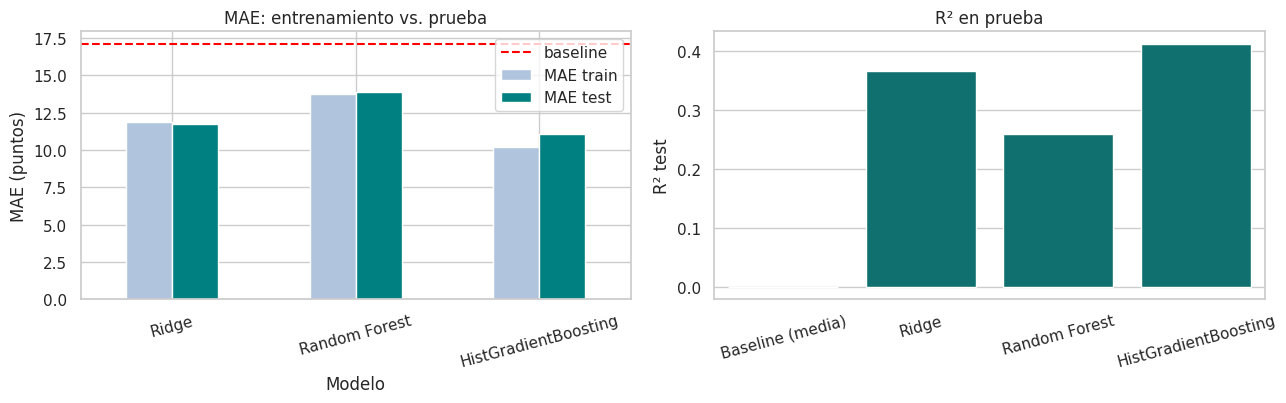

In [ ]:
def metricas(y_real, y_pred):
    return {"R²": r2_score(y_real, y_pred),
            "MAE": mean_absolute_error(y_real, y_pred),
            "RMSE": mean_squared_error(y_real, y_pred) ** 0.5,
            "% a ≤10 pts": 100 * np.mean(np.abs(y_real - y_pred) <= 10)}

pred_test, tabla = {}, []
for nombre, mod in modelos.items():
    pred_test[nombre] = mod.predict(X_test)
    tr = metricas(y_train, mod.predict(X_train))
    te = metricas(y_test, pred_test[nombre])
    tabla.append({"Modelo": nombre, "R² train": tr["R²"], "R² test": te["R²"], "MAE train": tr["MAE"],
                  "MAE test": te["MAE"], "RMSE test": te["RMSE"], "% a ≤10 pts (test)": te["% a ≤10 pts"]})
resultados = pd.DataFrame(tabla).set_index("Modelo")
display(resultados.round(3))

MAE_BASE = resultados.loc["Baseline (media)", "MAE test"]
resultados["Mejora MAE vs baseline %"] = 100 * (1 - resultados["MAE test"] / MAE_BASE)
print("\nMejora del MAE respecto al baseline:")
print(resultados["Mejora MAE vs baseline %"].round(1).to_string())

MEJOR = resultados.drop(index="Baseline (media)")["MAE test"].idxmin()
print(f"\nModelo con menor MAE en prueba: {MEJOR}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
resultados.drop(index="Baseline (media)")[["MAE train", "MAE test"]].plot(kind="bar", ax=ax[0], color=["lightsteelblue", "teal"])
ax[0].axhline(MAE_BASE, color="red", ls="--", label="baseline"); ax[0].set_ylabel("MAE (puntos)"); ax[0].legend()
ax[0].set_title("MAE: entrenamiento vs. prueba"); ax[0].tick_params(axis="x", rotation=15)
sns.barplot(x=resultados.index, y=resultados["R² test"], ax=ax[1], color="teal")
ax[1].set_title("R² en prueba"); ax[1].set_xlabel(""); ax[1].tick_params(axis="x", rotation=15)
plt.tight_layout(); guardar("06_comparacion_modelos"); plt.show()

### 📌 Interpretación de las métricas
| Modelo | R² test | MAE test | Mejora vs. baseline | Predicciones a ≤ 10 pts |
|---|---|---|---|---|
| Baseline (media) | ≈ 0,00 | 17,09 | — | 31,9% |
| Ridge | 0,365 | 11,72 | −31,4% | 58,7% |
| Random Forest | 0,260 | 13,89 | −18,7% | 43,6% |
| **HistGradientBoosting** | **0,412** | **11,08** | **−35,1%** | **61,7%** |

**Cómo leerlas.**
- **MAE 11,08:** en promedio el modelo se equivoca en **±11 puntos** en una escala de 0 a 100 (RMSE 15,7, mayor porque penaliza los errores grandes). Seis de cada diez predicciones quedan a ≤ 10 puntos del valor real.
- **R² 0,41:** el modelo explica el **41% de la varianza** de la popularidad; **el 59% restante queda sin explicar**. Es una mejora real y significativa sobre el *baseline*, pero modesta: las metas del EP1 (R² ≥ 0,85; MAE < 5,5) eran irreales para estos datos.
- **Sobreajuste:** HGB rinde mejor en entrenamiento (R² 0,52; MAE 10,2) que en prueba (R² 0,41; MAE 11,1); hay una brecha moderada. Ridge casi no tiene brecha (0,354 → 0,365).

**Coherencia en la elección del modelo.** HGB es el mejor en **todas** las métricas a la vez: MAE en validación cruzada, MAE y R² en prueba, % a ≤ 10 puntos y la métrica de negocio de la sección 8.5 (Precisión@5%). Ridge queda a solo 0,64 puntos de MAE y es la alternativa si se prioriza la **interpretabilidad**.

### 🎯 8.3 Diagnóstico del mejor modelo: ¿dónde se equivoca?
**Qué hacemos:** gráfico de valor real vs. predicho y distribución de los residuos del mejor modelo; además, el error promedio por tramos de popularidad.
**Por qué:** un MAE global puede esconder errores sistemáticos. Si el modelo "encoge" las predicciones hacia la media, subestimará justamente a los hits, que son lo que le interesa a la empresa.

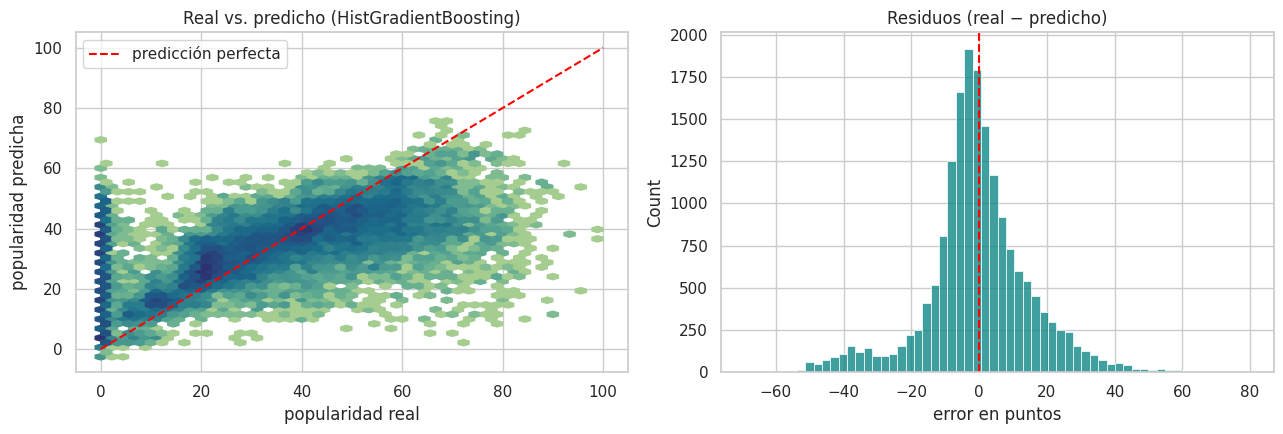

Error por tramo de popularidad real:


,canciones,pred_media,real_medio,MAE
tramo,,,,
0,1777,24.4,0.0,24.4
1–30,6500,25.9,19.0,7.8
31–50,5616,38.2,40.6,6.0
51–70,3423,43.9,58.7,15.0
71–100,540,42.4,76.6,34.2


In [ ]:
p = pred_test[MEJOR]
res = y_test - p

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
hb = ax[0].hexbin(y_test, p, gridsize=45, cmap="crest", mincnt=1, bins="log")
ax[0].plot([0, 100], [0, 100], "r--", label="predicción perfecta")
ax[0].set_xlabel("popularidad real"); ax[0].set_ylabel("popularidad predicha"); ax[0].legend()
ax[0].set_title(f"Real vs. predicho ({MEJOR})")
sns.histplot(res, bins=60, ax=ax[1], color="teal")
ax[1].axvline(0, color="red", ls="--"); ax[1].set_title("Residuos (real − predicho)"); ax[1].set_xlabel("error en puntos")
plt.tight_layout(); guardar("07_diagnostico_modelo"); plt.show()

tramos = pd.cut(y_test, [-0.1, 0.1, 30, 50, 70, 100], labels=["0", "1–30", "31–50", "51–70", "71–100"])
por_tramo = pd.DataFrame({"tramo": tramos, "real": y_test, "pred": p, "err_abs": np.abs(res)}).groupby("tramo").agg(
    canciones=("real", "size"), pred_media=("pred", "mean"), real_medio=("real", "mean"), MAE=("err_abs", "mean"))
print("Error por tramo de popularidad real:")
display(por_tramo.round(1))

### 📌 Interpretación del diagnóstico del modelo
**Hallazgo.** El modelo **comprime las predicciones hacia la media** (~33): se equivoca poco en el centro y mucho en los extremos.

| Popularidad real | Predicha en promedio | Real en promedio | MAE |
|---|---|---|---|
| 0 | 24,4 | 0,0 | 24,4 |
| 1–30 | 25,9 | 19,0 | 7,8 |
| 31–50 | 38,2 | 40,6 | **6,0** |
| 51–70 | 43,9 | 58,7 | 15,0 |
| **71–100 (hits)** | **42,4** | **76,6** | **34,2** |

En el histograma de residuos, la cola izquierda (errores de −20 a −50) corresponde en buena parte a canciones con popularidad 0 que el modelo predice cerca de 24, y la cola derecha a hits subestimados.

**Implicancia para la empresa.** Los *hits*, que son lo que le interesa a un sello, son justamente lo que peor se predice en magnitud (**subestimados en ~34 puntos**). Por eso el modelo **sirve para ordenar canciones, no para pronosticar su popularidad exacta**: "predicción: 45" no significa que esa canción tendrá 45. Los ceros reales tampoco se detectan (se predice ~24 para canciones con popularidad 0).

### 🎯 8.4 ¿Qué aporta cada grupo de variables? Ablación e importancia
**Qué hacemos:** (a) reentrenamos el mejor modelo con **tres conjuntos de variables**: solo audio y metadatos, solo género, y todas; (b) medimos la **importancia por permutación** (cuánto empeora el MAE al desordenar cada variable en el *test*; el género se desordena como un solo bloque).
**Por qué:** responde directamente la pregunta de negocio *"¿el audio explica la popularidad?"* y, en caso contrario, qué sí lo hace.

,R² test,MAE test
Variables usadas,,
Solo audio + metadatos musicales,0.108,15.357
Solo género,0.394,11.126
Audio + género (modelo completo),0.412,11.080


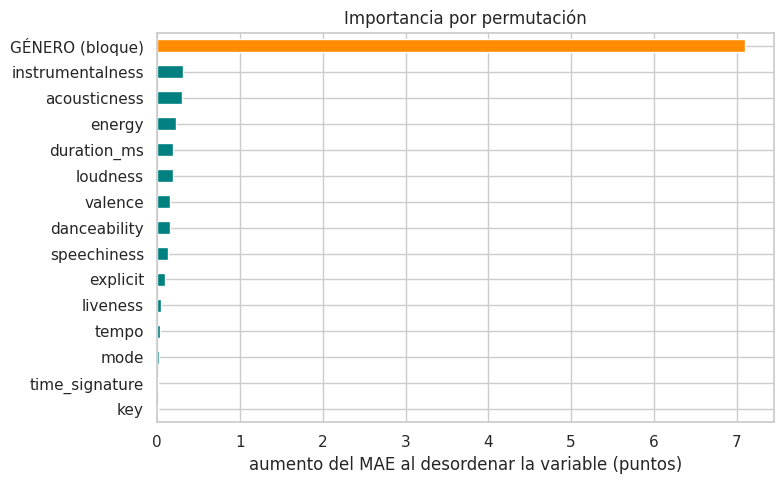

GÉNERO (bloque)     7.095
instrumentalness    0.312
acousticness        0.296
energy              0.233
duration_ms         0.192
loudness            0.186
valence             0.160
danceability        0.157
speechiness         0.132
explicit            0.090
liveness            0.051
tempo               0.035
mode                0.017
time_signature      0.005
key                 0.005


In [ ]:
mejor_est = modelos[MEJOR].named_steps["modelo"]
conjuntos = {
    "Solo audio + metadatos musicales": (NUM_COLS, CAT_COLS, []),
    "Solo género": ([], [], GEN_COLS),
    "Audio + género (modelo completo)": (NUM_COLS, CAT_COLS, GEN_COLS),
}
filas = []
for nombre, (n_, c_, g_) in conjuntos.items():
    cols = n_ + c_ + g_
    pipe = Pipeline([("prep", make_prep(n_, c_, g_)), ("modelo", clone(mejor_est))]).fit(X_train[cols], y_train)
    m = metricas(y_test, pipe.predict(X_test[cols]))
    filas.append({"Variables usadas": nombre, "R² test": m["R²"], "MAE test": m["MAE"]})
ablacion = pd.DataFrame(filas).set_index("Variables usadas")
display(ablacion.round(3))

# Importancia por permutación (grupos de variables)
rng = np.random.RandomState(SEED)
mae_ref = mean_absolute_error(y_test, modelos[MEJOR].predict(X_test))
grupos_var = {c: [c] for c in AUDIO + ["mode", "explicit", "key", "time_signature"]}
grupos_var["GÉNERO (bloque)"] = GEN_COLS
imp = {}
for nombre, cols in grupos_var.items():
    aumentos = []
    for _ in range(3):
        Xp = X_test.copy()
        perm = rng.permutation(len(Xp))
        Xp[cols] = Xp[cols].to_numpy()[perm]
        aumentos.append(mean_absolute_error(y_test, modelos[MEJOR].predict(Xp)) - mae_ref)
    imp[nombre] = np.mean(aumentos)
imp = pd.Series(imp).sort_values()

plt.figure(figsize=(8, 5))
imp.plot(kind="barh", color=["darkorange" if "GÉNERO" in i else "teal" for i in imp.index])
plt.xlabel("aumento del MAE al desordenar la variable (puntos)"); plt.title("Importancia por permutación")
plt.tight_layout(); guardar("08_importancia_variables"); plt.show()
print(imp.sort_values(ascending=False).round(3).to_string())

### 📌 Interpretación: ¿qué explica la popularidad?
| Variables usadas | R² test | MAE test |
|---|---|---|
| Solo audio + metadatos musicales | 0,108 | 15,36 |
| **Solo género** | **0,394** | **11,13** |
| Audio + género | 0,412 | 11,08 |

**Hallazgo.**
- El **audio por sí solo explica ~11% de la varianza** (más que el 1,7% de la mejor correlación individual, porque el modelo capta relaciones no lineales, pero sigue siendo poco).
- El **género por sí solo explica ~39%**, y agregar todo el audio sube el R² solo **+0,018**.
- En la importancia por permutación, desordenar el **bloque de género** empeora el MAE en **+7,1 puntos**, mientras que la variable de audio más importante (`instrumentalness`) lo empeora solo +0,31.

**Implicancia para la empresa.** Respuesta a la pregunta central: **el sonido de una canción explica poco su popularidad; lo que más ayuda a anticiparla es su género.** Precaución: esto **no significa que el género cause la popularidad**. En este dataset el género está mezclado con los sesgos de la fuente (los ceros y la cuota de 1.000 canciones por género), de modo que parte de su poder predictivo es un reflejo de cómo se construyó el dataset. La empresa no debería esperar que "sonar como un hit" garantice resultados.

### 🎯 8.5 KPIs de negocio: ¿sirve para priorizar canciones?
**Qué hacemos:** simulamos la decisión real de un equipo de A&R: **ordenar las canciones de prueba por el puntaje del modelo y quedarse con el 5% superior**. Medimos cuántas de ellas son realmente *hits* (Precisión@5%), cuántas veces mejor que elegir al azar (Lift) y qué porción de todos los hits se captura (Recall@5%). Como complemento, entrenamos un **clasificador de hits** (`HistGradientBoostingClassifier` con clases balanceadas), porque los hits son solo una pequeña fracción del catálogo.
**Por qué:** las métricas técnicas (MAE, R²) no le dicen a la empresa si el modelo le sirve para decidir. Estas sí.

,Precisión@5%,Lift vs azar,Recall@5%,Hits por 100 promovidas
Ridge,11.32,3.33,16.64,11.32
Random Forest,8.86,2.61,13.01,8.86
HistGradientBoosting,15.13,4.45,22.24,15.13
Clasificador de hits (HGB),29.48,8.67,43.33,29.48
Elegir al azar,4.15,1.22,6.10,4.15



Tasa de hits en el conjunto de prueba (línea base): 3.40%
Clasificador de hits -> ROC-AUC: 0.911 | PR-AUC: 0.283 (PR-AUC de un modelo al azar = 0.034)


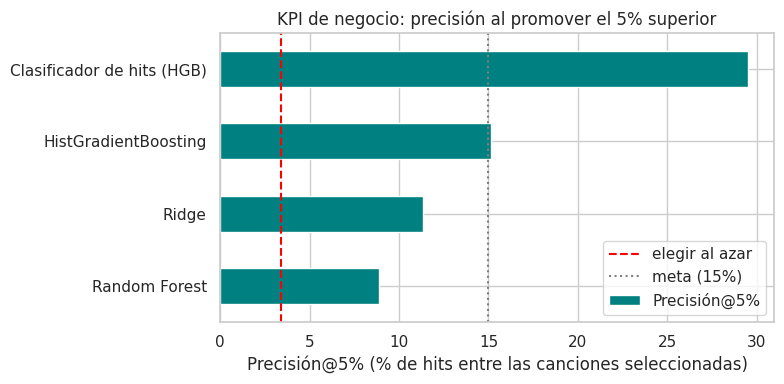

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

FRAC = 0.05
hits_test = (y_test >= HIT)
BASE_TEST = hits_test.mean()

def kpis_negocio(puntaje, frac=FRAC):
    k = int(len(puntaje) * frac)
    top = np.argsort(-puntaje)[:k]
    prec = hits_test[top].mean()
    return {"Precisión@5%": 100 * prec, "Lift vs azar": prec / BASE_TEST, "Recall@5%": 100 * hits_test[top].sum() / hits_test.sum(),
            "Hits por 100 promovidas": 100 * prec}

filas = {n: kpis_negocio(pred_test[n]) for n in modelos if n != "Baseline (media)"}

clf = Pipeline([("prep", make_prep()),
                ("modelo", HistGradientBoostingClassifier(class_weight="balanced", learning_rate=0.1, max_leaf_nodes=31, random_state=SEED))])
clf.fit(X_train, (y_train >= HIT).astype(int))
prob = clf.predict_proba(X_test)[:, 1]
filas["Clasificador de hits (HGB)"] = kpis_negocio(prob)

rng2 = np.random.RandomState(SEED)
filas["Elegir al azar"] = kpis_negocio(rng2.rand(len(y_test)))

kpi_tabla = pd.DataFrame(filas).T
display(kpi_tabla.round(2))
print(f"\nTasa de hits en el conjunto de prueba (línea base): {100*BASE_TEST:.2f}%")
print(f"Clasificador de hits -> ROC-AUC: {roc_auc_score(hits_test, prob):.3f} | PR-AUC: {average_precision_score(hits_test, prob):.3f} "
      f"(PR-AUC de un modelo al azar = {BASE_TEST:.3f})")

plt.figure(figsize=(8, 4))
k_plot = kpi_tabla.drop(index="Elegir al azar")["Precisión@5%"].sort_values()
k_plot.plot(kind="barh", color="teal")
plt.axvline(100 * BASE_TEST, color="red", ls="--", label="elegir al azar"); plt.axvline(15, color="gray", ls=":", label="meta (15%)")
plt.xlabel("Precisión@5% (% de hits entre las canciones seleccionadas)"); plt.legend(); plt.title("KPI de negocio: precisión al promover el 5% superior")
plt.tight_layout(); guardar("09_kpi_negocio"); plt.show()

### 📌 Interpretación de los KPIs de negocio
Simulando promover el **5% de canciones mejor puntuadas** (≈ 890 de las 17.856 de prueba):

| Estrategia | Precisión@5% | Lift vs. azar | Recall@5% |
|---|---|---|---|
| Elegir al azar | 4,2% | 1,2× | 6,1% |
| Random Forest | 8,9% | 2,6× | 13,0% |
| Ridge | 11,3% | 3,3× | 16,6% |
| HGB (regresión) | 15,1% | 4,5× | 22,2% |
| **Clasificador de hits (HGB)** | **29,5%** | **8,7×** | **43,3%** |

**Hallazgo.**
- El **clasificador de hits** es la mejor herramienta para priorizar: entre las canciones que selecciona, **casi 3 de cada 10 son hits** (vs. 3,4% de base) y captura **43 de cada 100 hits del catálogo con solo el 5% de las promociones**. Su PR-AUC es 0,283 frente a 0,034 de un modelo al azar (≈ 8×) y su ROC-AUC es 0,911.
- La fila "al azar" arroja 4,2% en vez de 3,4% solo por variación de muestreo.
- **Honestidad sobre los límites:** (1) 29,5% significa que **~7 de cada 10 canciones promovidas no serán hits** y que más de la mitad de los hits quedan fuera de la selección; (2) la meta del EP1 (precisión ≥ 40%) **no se alcanza**; (3) el regresor HGB cumple la meta de 15% por un margen mínimo (15,1%): con ~890 canciones seleccionadas, el error de muestreo es de ±1,2 puntos, por lo que debe leerse como "alrededor de la meta".

**Implicancia para la empresa.** Usado como **filtro de priorización** (no como decisor único), el modelo multiplica por ~9 la tasa de aciertos frente a elegir al azar. Esto se traduce en **29 hits por cada 100 canciones promovidas en vez de 3**, aunque siempre bajo la advertencia de que "hit" se define con la métrica de Spotify (sección 6).

### 🎯 8.6 Análisis de sensibilidad: ¿qué pasa con los ceros de popularidad?
**Qué hacemos:** reentrenamos el mejor modelo **sin las canciones de popularidad 0** y lo evaluamos sobre canciones de prueba con popularidad > 0.
**Por qué:** en el EDA vimos que los ceros no se comportan como impopularidad real. Si los ceros son ruido de la fuente, el desempeño medido sobre canciones con datos válidos debería cambiar. Esto prueba la robustez de las conclusiones.

In [ ]:
nz_tr = y_train > 0
nz_te = y_test > 0
pipe_nz = Pipeline([("prep", make_prep()), ("modelo", clone(mejor_est))]).fit(X_train[nz_tr], y_train[nz_tr])

m_completo_nz = metricas(y_test[nz_te], pred_test[MEJOR][nz_te])
m_nz = metricas(y_test[nz_te], pipe_nz.predict(X_test[nz_te]))
sens = pd.DataFrame({"Modelo original, evaluado solo en canciones con pop > 0": m_completo_nz,
                     "Modelo reentrenado sin ceros, evaluado en pop > 0": m_nz}).T
display(sens.round(3))
print(f"Canciones sin ceros: train {nz_tr.sum():,} | test {nz_te.sum():,}")

# ¿Sigue dominando el género cuando se excluyen los ceros? (misma ablación de 8.4, pero sin ceros)
filas_s = []
for nombre, (n_, c_, g_) in conjuntos.items():
    cols = n_ + c_ + g_
    pp = Pipeline([("prep", make_prep(n_, c_, g_)), ("modelo", clone(mejor_est))]).fit(X_train[nz_tr][cols], y_train[nz_tr])
    mm = metricas(y_test[nz_te], pp.predict(X_test[nz_te][cols]))
    filas_s.append({"Variables usadas (sin ceros)": nombre, "R² test": mm["R²"], "MAE test": mm["MAE"]})
print("\nAblación sin canciones de popularidad 0:")
display(pd.DataFrame(filas_s).set_index("Variables usadas (sin ceros)").round(3))

,R²,MAE,RMSE,% a ≤10 pts
"Modelo original, evaluado solo en canciones con pop > 0",0.441,9.603,13.574,66.074
"Modelo reentrenado sin ceros, evaluado en pop > 0",0.517,8.977,12.606,68.114


Canciones sin ceros: train 64,161 | test 16,079

Ablación sin canciones de popularidad 0:


,R² test,MAE test
Variables usadas (sin ceros),,
Solo audio + metadatos musicales,0.184,13.050
Solo género,0.495,9.264
Audio + género (modelo completo),0.517,8.977


### 📌 Interpretación del análisis de sensibilidad
**Hallazgo.** Si evaluamos solo sobre canciones con popularidad > 0, el modelo original sube a R² 0,441 (MAE 9,60), y **reentrenado sin ceros** alcanza **R² 0,517 (MAE 8,98)**. Los ceros, por lo tanto, **agregan ruido** y limitan el desempeño. Además, la ablación sin ceros muestra que el **género sigue dominando** (R² 0,495 solo con género vs. 0,184 solo con audio), aunque el audio gana peso (0,108 → 0,184).

**Implicancia.** (1) Los ceros **no explican por sí solos** la importancia del género: la conclusión de 8.4 es robusta. (2) Si los ceros fueran datos faltantes (hipótesis de 5.2), la capacidad predictiva real sobre datos válidos sería mayor que la reportada. (3) **Recomendación:** antes de usar el modelo en producción, la empresa debería verificar con Spotify o con datos propios (reproducciones reales) qué significa un 0.

---
# 9. Modelado no supervisado: segmentación de canciones

**Problema de negocio:** ¿existen **perfiles sonoros** naturales dentro del catálogo (por ejemplo "bailable y enérgico" vs. "acústico y tranquilo")? Un equipo de A&R podría usarlos para organizar su catálogo, comparar un lanzamiento contra canciones del mismo perfil y detectar si algún perfil concentra más hits.

### 🎯 9.1 Técnica y preparación
**Qué hacemos:** aplicamos **K-Means** sobre las 10 variables de audio **sin usar `popularity`** (así los segmentos describen el *sonido*, y luego comprobamos si se relacionan con el éxito). Antes: `duration_ms` pasa a escala logarítmica (tiene una cola muy larga) y todo se estandariza, porque K-Means usa distancias y no debe dominar la variable con mayor escala.
**Por qué K-Means:** es el algoritmo estándar para segmentación, es escalable a ~90.000 canciones, y sus centroides son fáciles de interpretar para el negocio. Para visualizar usamos **PCA** (reducción a 2 dimensiones).

In [ ]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

Xc = tracks[AUDIO].copy()
Xc["duration_ms"] = np.log1p(Xc["duration_ms"])
Z = StandardScaler().fit_transform(Xc)

pca = PCA(n_components=2, random_state=SEED).fit(Z)
Z2 = pca.transform(Z)
print(f"Varianza explicada por los 2 primeros componentes de PCA: {100*pca.explained_variance_ratio_.sum():.1f}%")

Varianza explicada por los 2 primeros componentes de PCA: 44.2%


### 🎯 9.2 Elección del número de grupos *k*
**Qué hacemos:** probamos *k* = 2 a 8 y calculamos la **inercia** (método del codo) y el **coeficiente de silueta** (qué tan separados y compactos son los grupos; va de −1 a 1, y valores < 0,25 indican estructura débil).
**Por qué:** *k* no se conoce de antemano; se decide con métricas **y** con criterio de negocio (grupos interpretables y no demasiado pequeños).

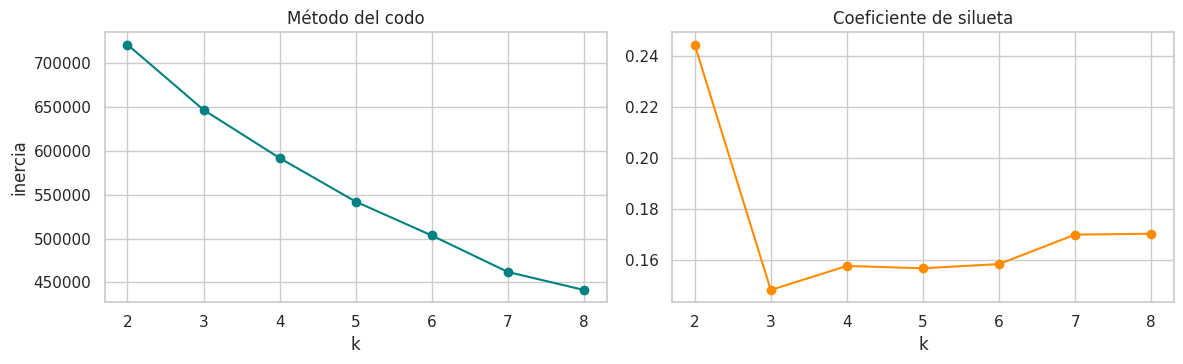

 k  inercia  silueta
 2 721067.0    0.244
 3 646673.0    0.148
 4 591772.0    0.158
 5 542062.0    0.157
 6 503453.0    0.158
 7 461879.0    0.170
 8 441340.0    0.170


In [ ]:
ks = range(2, 9)
inercia, sil = [], []
muestra_sil = np.random.RandomState(SEED).choice(len(Z), 10000, replace=False)
for k in ks:
    km = KMeans(n_clusters=k, n_init=5, random_state=SEED).fit(Z)
    inercia.append(km.inertia_)
    sil.append(silhouette_score(Z[muestra_sil], km.labels_[muestra_sil]))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(list(ks), inercia, "o-", color="teal"); ax[0].set_title("Método del codo"); ax[0].set_xlabel("k"); ax[0].set_ylabel("inercia")
ax[1].plot(list(ks), sil, "o-", color="darkorange"); ax[1].set_title("Coeficiente de silueta"); ax[1].set_xlabel("k")
plt.tight_layout(); guardar("10_eleccion_k"); plt.show()
print(pd.DataFrame({"k": list(ks), "inercia": np.round(inercia, 0), "silueta": np.round(sil, 3)}).to_string(index=False))

### 📌 Interpretación de la elección de *k*
**Hallazgo.** El coeficiente de silueta es bajo en todos los casos (**máximo 0,244 en k = 2** y entre 0,148 y 0,170 para k = 3 a 8; ningún valor alcanza 0,25) y el codo no muestra un quiebre pronunciado (la inercia baja gradualmente de 721.000 a 441.000). Esto indica que el catálogo es un **continuo de sonidos** más que grupos bien separados.

**Decisión.** Elegimos **k = 4**. Matemáticamente k = 2 tiene la mejor silueta, pero solo separaría "tranquilo" de "enérgico", demasiado grueso para el negocio; entre k = 3 y k = 6 la silueta es prácticamente igual (≈ 0,15–0,16), así que el criterio decisivo es la **interpretabilidad**: con k = 4 se obtienen cuatro perfiles sonoros claramente distinguibles (9.4). Se declara que la elección se hizo por criterio de negocio y no por máxima silueta.

### 🎯 9.3 Ajuste final, estabilidad y visualización
**Qué hacemos:** ajustamos K-Means con el *k* elegido, comprobamos su **estabilidad** (¿salen los mismos grupos con otra semilla? se mide con el índice de Rand ajustado, ARI, donde 1 = idénticos) y proyectamos los grupos con PCA.
**Por qué:** un segmento que cambia según la semilla no sirve para decidir nada.

k elegido = 4
Estabilidad entre semillas (ARI): 0.834
Silueta global (muestra): 0.158

Tamaño de cada grupo:
cluster
0    19055
1    30414
2     1131
3    38983


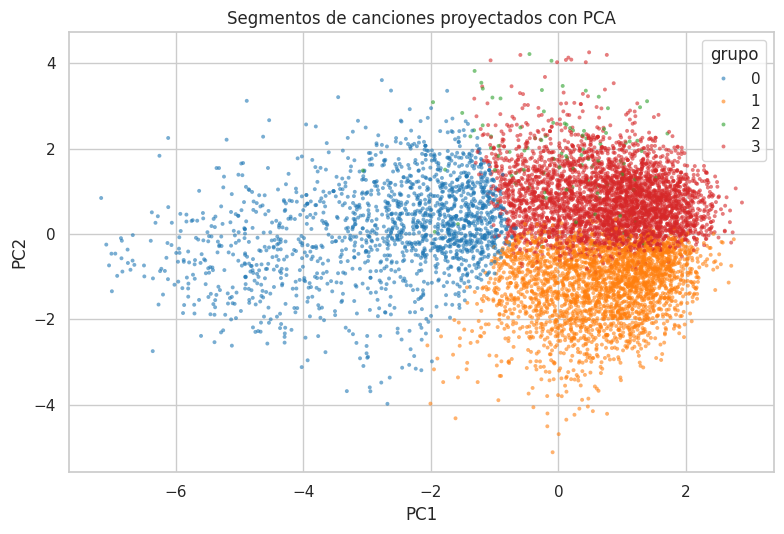

In [ ]:
K = 4
km = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(Z)
tracks["cluster"] = km.labels_

km_b = KMeans(n_clusters=K, n_init=10, random_state=7).fit(Z)
print(f"k elegido = {K}")
print(f"Estabilidad entre semillas (ARI): {adjusted_rand_score(km.labels_, km_b.labels_):.3f}")
print(f"Silueta global (muestra): {silhouette_score(Z[muestra_sil], km.labels_[muestra_sil]):.3f}")
print("\nTamaño de cada grupo:")
print(tracks["cluster"].value_counts().sort_index().to_string())

vis = np.random.RandomState(SEED).choice(len(Z2), 8000, replace=False)
plt.figure(figsize=(8, 5.5))
sns.scatterplot(x=Z2[vis, 0], y=Z2[vis, 1], hue=km.labels_[vis], palette="tab10", s=8, alpha=0.6, linewidth=0)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("Segmentos de canciones proyectados con PCA"); plt.legend(title="grupo")
plt.tight_layout(); guardar("11_clusters_pca"); plt.show()

### 🎯 9.4 Perfil de cada segmento y relación con la popularidad
**Qué hacemos:** describimos cada grupo con (a) el promedio estandarizado de sus variables de audio (mapa de calor), (b) su tamaño, popularidad media, tasa de hits y % de ceros, y (c) los géneros que más lo componen. Medimos además qué fracción de la varianza de la popularidad explican los grupos (η²).
**Por qué:** un segmento solo es útil para el negocio si se puede **describir** y si dice algo sobre el éxito comercial.

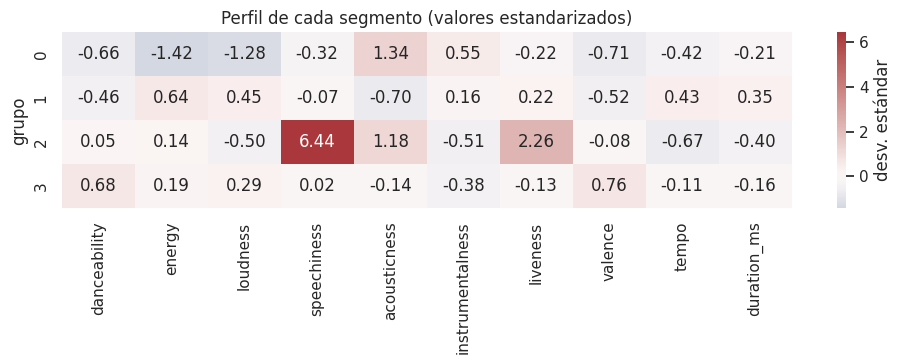

,canciones,pop_media,tasa_hits,pct_ceros,lift_hits
cluster,,,,,
0,19055,30.38,1.70,14.43,0.49
1,30414,33.59,2.71,6.49,0.78
2,1131,24.93,0.53,3.45,0.15
3,38983,34.50,5.04,11.75,1.45


Promedios reales de audio por grupo:


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
cluster,,,,,,,,,,
0,0.45,0.27,-15.10,0.05,0.78,0.35,0.17,0.28,109.68,216102.49
1,0.48,0.80,-6.17,0.08,0.09,0.22,0.26,0.33,135.18,262351.44
2,0.57,0.67,-11.05,0.82,0.73,0.01,0.66,0.45,102.24,215928.59
3,0.68,0.68,-6.96,0.09,0.28,0.05,0.19,0.67,118.93,210225.81


Géneros más frecuentes dentro de cada segmento (% de sus canciones):
  grupo 0: new-age (5%), ambient (5%), classical (4%), opera (4%), sleep (4%)
  grupo 1: death-metal (3%), grindcore (3%), black-metal (3%), metalcore (3%), heavy-metal (3%)
  grupo 2: comedy (71%), show-tunes (4%), kids (2%), funk (2%), children (2%)
  grupo 3: reggaeton (2%), latino (2%), reggae (2%), dancehall (2%), salsa (2%)

η² (varianza de la popularidad explicada por el segmento): 0.008


In [ ]:
perfil_z = pd.DataFrame(Z, columns=AUDIO).groupby(tracks["cluster"].to_numpy()).mean()
perfil_real = tracks.groupby("cluster")[AUDIO].mean()

plt.figure(figsize=(10, 3.8))
sns.heatmap(perfil_z, annot=True, fmt=".2f", cmap="vlag", center=0, cbar_kws={"label": "desv. estándar"})
plt.title("Perfil de cada segmento (valores estandarizados)"); plt.ylabel("grupo")
plt.tight_layout(); guardar("12_perfil_clusters"); plt.show()

resumen_cl = tracks.groupby("cluster").agg(canciones=("popularity", "size"), pop_media=("popularity", "mean"),
                                           tasa_hits=("es_hit", "mean"), pct_ceros=("popularity", lambda s: (s == 0).mean()))
resumen_cl["tasa_hits"] *= 100; resumen_cl["pct_ceros"] *= 100
resumen_cl["lift_hits"] = resumen_cl["tasa_hits"] / (100 * TASA_HITS)
display(resumen_cl.round(2))
print("Promedios reales de audio por grupo:")
display(perfil_real.round(2))

# Géneros dominantes de cada segmento
print("Géneros más frecuentes dentro de cada segmento (% de sus canciones):")
for c in sorted(tracks["cluster"].unique()):
    sub = tracks.loc[tracks["cluster"] == c, GEN_COLS].mean().sort_values(ascending=False).head(5) * 100
    print(f"  grupo {c}: " + ", ".join(f"{i.replace('gen_', '')} ({v:.0f}%)" for i, v in sub.items()))

# η²: fracción de la varianza de popularity explicada por el segmento
medias = tracks.groupby("cluster")["popularity"].transform("mean")
eta2 = ((medias - tracks["popularity"].mean()) ** 2).sum() / ((tracks["popularity"] - tracks["popularity"].mean()) ** 2).sum()
print(f"\nη² (varianza de la popularidad explicada por el segmento): {eta2:.3f}")

### 📌 Interpretación de los segmentos
**Calidad del agrupamiento.** Estabilidad entre semillas **ARI = 0,83** (los grupos son reproducibles), pero **silueta = 0,158** (bordes difusos) y los 2 primeros componentes de PCA explican solo 44% de la varianza, por eso en el gráfico los grupos se superponen. Son perfiles útiles para describir, no fronteras nítidas.

| Segmento | Perfil (promedios) | Géneros dominantes | Canciones | Tasa de hits |
|---|---|---|---|---|
| **0. Acústico / ambiental** | energy 0,27; acousticness 0,78; loudness −15 dB; valence 0,28 | new-age, ambient, classical, opera, sleep | 19.055 (21%) | 1,7% (0,5×) |
| **1. Intenso (rock / metal)** | energy 0,80; acousticness 0,09; loudness −6,2 dB; tempo 135 | death-metal, grindcore, black-metal, metalcore | 30.414 (34%) | 2,7% (0,8×) |
| **2. Hablado / comedia** | speechiness 0,82; liveness 0,66; instrumentalness 0,01 | *comedy* (71%), show-tunes, kids | 1.131 (1%) | 0,5% (0,2×) |
| **3. Bailable y positivo** | danceability 0,68; valence 0,67; energy 0,68 | reggaeton, latino, reggae, dancehall, salsa | 38.983 (44%) | **5,0% (1,45×)** |

**Hallazgo clave.** Los segmentos coinciden con géneros, lo que valida que capturan "sonido". El segmento **bailable y positivo concentra más hits que el promedio** (5,0% vs. 3,5%) y los segmentos acústico y hablado, menos. Pero la relación es modesta: los segmentos explican **menos del 1% de la varianza de la popularidad (η² = 0,008)**, consistente con la sección 8.4 (el sonido casi no determina el éxito).

**Implicancia para la empresa.** Los segmentos sirven para (1) **comparar un lanzamiento con canciones de su mismo perfil** (benchmarking) y (2) **organizar el catálogo** y balancear el portafolio. No sirven para predecir el éxito. Además, hay un riesgo ético: el 44% del catálogo está en el segmento que más hits concentra; promover solo ese perfil **homogeneizaría** la oferta (ver sección 6.3).

---
# 10. Evaluación e interpretación de resultados

### 🎯 10.1 Cumplimiento de los KPIs definidos en la sección 1.4
**Qué hacemos:** contrastamos automáticamente cada meta con el resultado obtenido (las cifras salen de las celdas anteriores, no están escritas a mano).

In [ ]:
r = resultados.loc[MEJOR]
kp = kpi_tabla.loc[MEJOR]

def ok(c): return "✅ Cumple" if c else "❌ No cumple"
kpi_final = pd.DataFrame([
    ["Técnico", "MAE test ≤ 12", f"{r['MAE test']:.2f}", ok(r["MAE test"] <= 12)],
    ["Técnico", "Mejora MAE vs baseline ≥ 25%", f"{r['Mejora MAE vs baseline %']:.1f}%", ok(r["Mejora MAE vs baseline %"] >= 25)],
    ["Técnico", "R² test ≥ 0,30", f"{r['R² test']:.3f}", ok(r["R² test"] >= 0.30)],
    ["Negocio", "Precisión@5% ≥ 15%", f"{kp['Precisión@5%']:.1f}%  (azar: {100*BASE_TEST:.1f}%)", ok(kp["Precisión@5%"] >= 15)],
    ["Negocio", "Lift vs azar ≥ 3×", f"{kp['Lift vs azar']:.1f}×", ok(kp["Lift vs azar"] >= 3)],
    ["Negocio", "Hits por 100 promovidas > azar", f"{kp['Hits por 100 promovidas']:.1f} vs {100*BASE_TEST:.1f}", ok(kp["Hits por 100 promovidas"] > 100 * BASE_TEST)],
    ["Negocio", "Precisión@5% del clasificador de hits ≥ 15%", f"{kpi_tabla.loc['Clasificador de hits (HGB)', 'Precisión@5%']:.1f}%",
     ok(kpi_tabla.loc['Clasificador de hits (HGB)', 'Precisión@5%'] >= 15)],
], columns=["Tipo", "Meta", "Resultado", "Estado"])
display(kpi_final)
print(f"Modelo evaluado: {MEJOR}")

,Tipo,Meta,Resultado,Estado
0,Técnico,MAE test ≤ 12,11.08,✅ Cumple
1,Técnico,Mejora MAE vs baseline ≥ 25%,35.1%,✅ Cumple
2,Técnico,"R² test ≥ 0,30",0.412,✅ Cumple
3,Negocio,Precisión@5% ≥ 15%,15.1% (azar: 3.4%),✅ Cumple
4,Negocio,Lift vs azar ≥ 3×,4.5×,✅ Cumple
5,Negocio,Hits por 100 promovidas > azar,15.1 vs 3.4,✅ Cumple
6,Negocio,Precisión@5% del clasificador de hits ≥ 15%,29.5%,✅ Cumple


Modelo evaluado: HistGradientBoosting


### 📌 Interpretación del cumplimiento de KPIs
**Hallazgo.** Con las metas **redefinidas tras el EDA** (sección 1.4), todas se cumplen. La lectura honesta es esta:
- **Técnicos:** MAE 11,08 (≤ 12), mejora del 35% sobre el *baseline* y R² 0,41. Se cumplen, pero un R² de 0,41 implica que **59% de la variabilidad no se explica**.
- **Negocio:** el regresor HGB cumple Precisión@5% ≥ 15% **por un margen estrecho** (15,1%); el **clasificador** lo supera con holgura (29,5%, lift 8,7×).
- **Meta del EP1 no cumplida:** la precisión ≥ 40% planteada originalmente **no se alcanza** (29,5%). Era optimista para una tarea en la que el audio explica tan poco.

**Recomendación de modelo para la empresa.**
1. **Para priorizar:** usar el **clasificador de hits** (mayor precisión y recall al seleccionar el 5% superior).
2. **Para una estimación aproximada de popularidad:** HGB regresor, sabiendo que erra ±11 puntos y subestima mucho a los hits.
3. **Si se exige explicabilidad:** Ridge, con un costo de ~0,6 puntos de MAE.

En todos los casos el modelo es un **apoyo a la decisión**: de cada 10 canciones promovidas, ~7 no serán hits.

### 🎯 10.2 Equidad entre géneros: ¿el modelo trata igual a todos los estilos?
**Qué hacemos:** calculamos el error medio y el sesgo (predicho − real) del mejor modelo por género, en las canciones de prueba, para los géneros con al menos 100 canciones.
**Por qué:** en la sección 6 advertimos que los ceros se concentran en ciertos géneros; aquí medimos si eso se traduce en errores sistemáticos que perjudiquen a esos estilos.

In [ ]:
pred_mejor = pred_test[MEJOR]
test_df = tracks.iloc[idx_te].copy()
test_df["pred"] = pred_mejor
test_df["error"] = test_df["pred"] - test_df["popularity"]
test_df["abs_error"] = test_df["error"].abs()

filas_g = []
for c in GEN_COLS:
    s = test_df[test_df[c] == 1]
    if len(s) >= 100:
        filas_g.append({"género": c.replace("gen_", ""), "canciones_test": len(s), "pop_real_media": s["popularity"].mean(),
                        "pop_predicha_media": s["pred"].mean(), "sesgo (pred − real)": s["error"].mean(), "MAE": s["abs_error"].mean()})
eq = pd.DataFrame(filas_g).set_index("género").sort_values("sesgo (pred − real)")
print(f"Géneros analizados: {len(eq)}")
print("\nMás subestimados (el modelo predice MENOS popularidad de la real):")
display(eq.head(6).round(1))
print("Más sobreestimados (el modelo predice MÁS popularidad de la real):")
display(eq.tail(6).round(1))
print(f"Correlación entre pop. real media y sesgo por género: {eq['pop_real_media'].corr(eq['sesgo (pred − real)']):.2f}")

Géneros analizados: 114

Más subestimados (el modelo predice MENOS popularidad de la real):


,canciones_test,pop_real_media,pop_predicha_media,sesgo (pred − real),MAE
género,,,,,
pop,163,58.2,51.3,-7.0,22.2
folk,186,42.4,37.8,-4.6,14.5
acoustic,204,44.6,41.3,-3.3,12.8
chill,178,55.3,52.2,-3.1,8.8
blues,152,40.2,37.4,-2.8,19.4
british,190,46.2,43.5,-2.7,17.0


Más sobreestimados (el modelo predice MÁS popularidad de la real):


,canciones_test,pop_real_media,pop_predicha_media,sesgo (pred − real),MAE
género,,,,,
rockabilly,216,29.5,33.6,4.1,16.1
latin,220,6.3,10.9,4.7,13.8
country,195,15.7,20.6,5.0,23.4
house,197,31.3,36.3,5.0,29.9
dance,180,24.6,29.8,5.3,30.7
electro,192,32.9,41.4,8.5,32.0


Correlación entre pop. real media y sesgo por género: -0.57


### 📌 Interpretación de la equidad entre géneros
**Hallazgo.** El sesgo del modelo (predicho − real) tiene una **correlación de −0,57 con la popularidad real media del género**: el modelo **subestima los géneros populares** (*pop* −7,0 puntos; *folk* −4,6; *acoustic* −3,3) y **sobreestima los poco populares** (*electro* +8,5; *dance* +5,3; *house* +5,0; *country* +5,0; *latin* +4,7). Es la misma compresión hacia la media de 8.3, ahora por género. Además, el error absoluto es enorme en *dance* (30,7), *electro* (32,0) y *house* (29,9): son géneros donde la popularidad es "todo o nada" (muchos ceros y muchas canciones populares), y el modelo predice un valor intermedio que no corresponde a ninguno de los dos grupos.

**Implicancia para la empresa y ética.** (1) Varios géneros con muchos ceros (*latin*, *country*, *dance*) aparecen **sobreestimados**, o sea que el modelo no los castiga, pero **sí subestima al género más mainstream (*pop*)**. (2) El puntaje **no es comparable entre géneros**: conviene ordenar canciones **dentro de cada género o segmento**, y no con un ranking único. (3) Esto refuerza que el modelo debe revisarse por género antes de usarse en decisiones.

---
# 11. Recomendaciones, despliegue y conclusiones

### 🎯 11.1 Guardado del modelo (fase de despliegue)
**Qué hacemos:** guardamos el *pipeline* completo (preprocesamiento + modelo) y un archivo con sus métricas en `models/`, de modo que cualquiera pueda cargarlo y puntuar canciones nuevas sin volver a entrenar.

In [ ]:
import joblib, json
joblib.dump(modelos[MEJOR], "../models/modelo_popularidad.joblib")
meta = {"modelo": MEJOR, "semilla": SEED, "umbral_hit": HIT, "variables": FEAT_COLS[:len(NUM_COLS + CAT_COLS)] + ["gen_* (multi-hot, 114 géneros)"],
        "metricas_test": {k: round(float(v), 4) for k, v in resultados.loc[MEJOR][["R² test", "MAE test", "RMSE test"]].items()},
        "kpis_negocio_top5": {k: round(float(v), 3) for k, v in kpis_negocio(pred_test[MEJOR]).items()}}
with open("../models/modelo_popularidad_metricas.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, ensure_ascii=False, indent=2)

# Prueba de uso: puntuar 5 canciones nuevas con el modelo cargado
modelo_cargado = joblib.load("../models/modelo_popularidad.joblib")
ejemplo = tracks.iloc[idx_te].drop_duplicates("grupo").head(5)
print(pd.DataFrame({"canción": ejemplo["track_name"].to_numpy(), "artista": ejemplo["artists"].to_numpy(),
                    "popularidad real": ejemplo["popularity"].to_numpy(),
                    "predicha": modelo_cargado.predict(ejemplo[FEAT_COLS]).round(1)}).to_string(index=False))

        canción                              artista  popularidad real  predicha
         Comedy                          Gen Hoshino              73.0      47.9
 To Begin Again               Ingrid Michaelson;ZAYN              57.0      43.4
  Say Something A Great Big World;Christina Aguilera              74.0      54.3
I Won't Give Up                           Jason Mraz              69.0      45.4
     Bella Luna                           Jason Mraz               1.0      20.2


### 📌 11.2 Recomendaciones para el equipo de A&R
1. **Usar el modelo como filtro de priorización, no como decisor:** el 5% mejor puntuado por el clasificador contiene ~29% de hits frente a ~3% al azar.
2. **No interpretar la popularidad predicha como valor esperado:** el regresor subestima los hits en ~34 puntos; sirve para ordenar.
3. **No invertir en "sonar como un hit":** el audio explica poco (R² ≈ 0,11). Para mejorar la predicción habría que incorporar variables que hoy no existen: **audiencia previa del artista, presupuesto de promoción e inclusión en *playlists***.
4. **Comparar dentro del mismo género o segmento**, porque el puntaje no es comparable entre géneros (10.2).
5. **Validar la métrica de éxito antes de producción:** contrastar `popularity` con datos propios de la empresa (reproducciones, ventas) y aclarar qué significa un 0.
6. **Resguardos éticos:** no usar el modelo para descartar artistas o géneros, y reservar un cupo de promoción para canciones fuera del *top* para evitar la homogeneización.

### 📌 11.3 Limitaciones
- **Circularidad de la variable objetivo:** `popularity` es una métrica propietaria de Spotify; el modelo aprende a anticipar lo que la plataforma ya promueve.
- **Dataset no representativo:** cuota fija de 1.000 canciones por género; **sin fecha de extracción**, por lo que no sabemos si la popularidad corresponde a un mismo momento.
- **Ceros sospechosos** (probable artefacto de la fuente) que no podemos verificar con estos datos.
- **Variables ausentes:** artista, promoción y *playlists*, probablemente las más determinantes.
- **Hiperparámetros** en el borde de la grilla, sin intervalos de confianza para las métricas y segmentos con silueta baja.

### 📌 11.4 Conclusiones
1. **Pregunta central:** *las características de audio, por sí solas, explican poco la popularidad* (|r| < 0,13 individual; R² ≈ 0,11 con un modelo no lineal). El **género** explica bastante más (R² ≈ 0,39), pero en parte por sesgos de construcción del dataset.
2. **Aun así el modelo agrega valor:** HGB reduce el error 35% frente al *baseline* y el clasificador de hits multiplica por ~9 la precisión al priorizar el 5% superior.
3. **No supervisado:** el catálogo se organiza en **4 perfiles sonoros** (acústico, intenso, hablado, bailable) estables pero difusos; el bailable concentra más hits, aunque los perfiles explican <1% de la popularidad.
4. **Las metas iniciales del EP1 eran inalcanzables** y se corrigieron con evidencia del EDA; la precisión ≥ 40% tampoco se logró.
5. **Metodológicamente**, tratar la fuga de datos (canciones repetidas y versiones) fue esencial para que las métricas sean confiables.

### 📌 11.5 Próximos pasos
- Ampliar la búsqueda de hiperparámetros y evaluar el umbral de decisión del clasificador según el costo real de promover una canción que no es hit.
- Incorporar variables de artista y promoción (con revisión ética y de privacidad).
- Obtener datos con fecha para analizar la popularidad en el tiempo y verificar el significado de los ceros.
- Evaluar otros umbrales de "hit" y usar los segmentos como variable adicional del modelo.

### 📌 11.6 Entregables y reproducibilidad
| Entregable | Ubicación |
|---|---|
| Informe técnico (este notebook) | `notebooks/Informe_Tecnico.ipynb` |
| Informe en Markdown | `README.md` |
| Datos | `data/Spotify_Tracks_Dataset.csv` |
| Gráficos generados | `images/` |
| Modelo entrenado y métricas | `models/` |
| Dependencias | `requirements.txt` |